# Credit Card Fraud Detection — Model Validation under Extreme Class Imbalance

**MSc project, completed in May 2026 · Original academic mark: 85/100 (Distinction).**

This is the portfolio edition of the MSc project. The benchmark was subsequently refined and trained on 24 November 2026. The displayed outputs come from the verified, matched-runtime reporting replay on 26 November 2026; no models were retrained during that replay. The academic mark applies to the original submission, not to the subsequent refinements.

This notebook studies the public ULB/Kaggle credit-card fraud dataset through duplicate-aware partitioning, development-only exploration, grouped model selection, operating-point optimisation, uncertainty quantification, chronological evaluation and model-artifact verification.

**Reading the notebook:** this is a public, read-only record of the executed analysis. Code and aggregate numerical/graphical outputs are preserved, with static HTML tables and nonessential execution metadata removed. The original private replay inputs (checkpoint files and model export) are not distributed. The included code documents the executed protocol; a fresh end-to-end run is not certified. Do not use Run All on this display derivative. See the repository README and technical report for methodology, scope and limitations.


In [1]:
_CCF_LAUNCH_MODE = 'replay'
import platform, importlib.metadata as _md, os, sys
if not __debug__: raise RuntimeError("Assertions disabled")
_expected = {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1', 'joblib': '1.6.0', 'threadpoolctl': '3.7.0', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'matplotlib': '3.10.0', 'nbclient': '0.10.4', 'nbformat': '5.11.1', 'jupyter-client': '7.4.9', 'ipykernel': '6.17.1'}
if not all((platform.python_version() if k=="python" else _md.version(k))==v for k,v in _expected.items()): raise RuntimeError("Kernel version mismatch")
if os.environ.get("CUDA_VISIBLE_DEVICES")!="": raise RuntimeError("CPU-only execution required")

## 1. Experimental protocol

The workflow is intentionally split into five parts.

**Part I — Broad exploration.** A development-only train/validation split is used to demonstrate scaling choices, resampling, class weighting and a range of model families. These experiments are diagnostic; they do not decide the final test result.

**Part II — Robust development-only selection.** Exact duplicate rows are removed and rows sharing the same model-feature vector are assigned to the same split/fold. Fixed candidates are evaluated out-of-fold. Random Forest and XGBoost tuning is nested inside each outer fold, so an observation cannot influence the hyperparameters used to score itself.

**Part III — Frozen evaluation and robustness.** After nested CV ranks the candidate procedures, a selected tuned procedure receives a final development-only search; a fixed procedure retains its preset configuration. Fresh grouped OOF scores from that exact frozen configuration select the operating threshold; only then is the holdout unlocked for reporting. A separate chronological protocol selects a model and threshold using past data only, then evaluates on a later window filtered for feature-fingerprint overlap with history.

**Primary ranking metric:** Average Precision (AP).  
**Operating-point metric:** F2, supplemented by Precision@k / Recall@k.  
**Why:** accuracy and ROC-AUC can look excellent on a dataset where fraud is well below 1%; AP and operating-point metrics expose rare-class performance more directly.

**Part IV — Chronological robustness.** A retrospective past-to-future comparison on the same dataset, not an independent external test.

**Part V — Artifact and reporting.** Package the frozen model and threshold, test reload parity, and report results and limitations.

**Historical scope:** the previous public notebook used test-derived scores to compare candidates and operating points. The revised programmatic holdout is frozen within its own protocol; it is not a prospectively unseen test. A conditional reconstruction using the current CSV and historical split procedure identified 11,447 overlapping exact row values (22 fraudulent). The old CSV digest is unavailable, so that overlap is an estimate, not an independently attested identity.

The prior public project used the entire historical dataset across modelling and EDA; the conditional exact-row (11,447) and fingerprint (12,198) overlaps (22 frauds each) specifically compare its 56,962-row test partition against the 56,696-row V5.1 grouped holdout. Earlier CSV identity is not established.

## 2. Imports, reproducibility and runtime controls


In [2]:
from __future__ import annotations

import os, sys
if not __debug__:
    raise RuntimeError("Assertions must be enabled for this benchmark.")
if globals().get("_CCF_LAUNCH_MODE") not in {"replay", "fresh"} or globals().get("_CCF_LAUNCH_MODE") != os.getenv("CCF_EXECUTION_MODE"):
    raise RuntimeError("Direct execution blocked. Use the isolated launcher and explicit mode.")

import hashlib
import importlib.metadata as importlib_metadata
import tempfile
import json
import os
import platform
import random
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

NOTEBOOK_VERSION = "V5.1"
RANDOM_STATE = 42
FAST_MODE = bool(int(os.getenv("FAST_MODE", "0")))
RUN_KERAS = bool(int(os.getenv("RUN_KERAS", "1")))
USE_GPU_FOR_XGBOOST = bool(int(os.getenv("XGB_GPU", "0")))
RUN_EXTENDED_CV = bool(int(os.getenv("RUN_EXTENDED_CV", "0" if FAST_MODE else "1")))
# Default to portable CPU execution, including TensorFlow. Set before its import.
if not USE_GPU_FOR_XGBOOST:
    os.environ["CUDA_VISIBLE_DEVICES"] = ""

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

OUTER_FOLDS = 2 if FAST_MODE else 3
INNER_FOLDS = 2 if FAST_MODE else 3
SEARCH_ITER = 1 if FAST_MODE else 10
RF_ESTIMATORS = 20 if FAST_MODE else 300
XGB_ESTIMATORS = 30 if FAST_MODE else 400
XGB_DEVICE = "cuda" if USE_GPU_FOR_XGBOOST else "cpu"

if FAST_MODE:
    print("FAST_MODE metrics are smoke-test only and must not be published as final evidence.")

print({
    "python": platform.python_version(),
    "fast_mode": FAST_MODE,
    "run_keras": RUN_KERAS,
    "run_extended_cv": RUN_EXTENDED_CV,
    "outer_folds": OUTER_FOLDS,
    "inner_folds": INNER_FOLDS,
    "search_iterations": SEARCH_ITER,
    "xgboost_device": XGB_DEVICE,
})


{'python': '3.13.18', 'fast_mode': False, 'run_keras': True, 'run_extended_cv': True, 'outer_folds': 3, 'inner_folds': 3, 'search_iterations': 10, 'xgboost_device': 'cpu'}


### Reproducibility note

Seeds reduce avoidable run-to-run variation, but GPU libraries and low-level numerical kernels are not guaranteed to be bit-for-bit deterministic across hardware/software stacks. The published run should therefore record package versions, dataset hash, hardware mode and random seeds rather than claiming absolute determinism.

`FAST_MODE=1` is a smoke-test mode. The portfolio run should use `FAST_MODE=0`. XGBoost and TensorFlow default to CPU for portability; GPU visibility is opt-in with `XGB_GPU=1`. Explicit `RUN_EXTENDED_CV=1` enables the extended candidates even in smoke mode. The smoke sample deliberately contains more fraud cases than a prevalence-preserving sample so SMOTE and small grouped folds can be exercised; its metrics are not evidence.

The completed reference run recorded Python 3.13.18, NumPy 2.4.6, pandas 2.2.3, SciPy 1.16.3, scikit-learn 1.6.1, imbalanced-learn 0.14.2, XGBoost 3.4.1, joblib 1.6.0, TensorFlow 2.21.0, Keras 3.13.2, matplotlib 3.10.0, threadpoolctl 3.7.0 and Papermill 2.7.0. These are historical environment records, not a guarantee that every wheel is currently obtainable. The completed reference run computed 57 work units and restored none; a separate prior smoke/resume experiment exercised checkpoint restoration. Changing source, data, environment or execution settings changes the run signature and must not silently reuse a different namespace.

## 3. Load and validate the dataset


In [3]:
MODEL_FEATURES = [*[f"V{i}" for i in range(1, 29)], "Amount"]
EXPECTED_COLUMNS = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]


def resolve_dataset_path() -> Path:
    env_path = os.getenv("CREDITCARD_DATA_PATH")
    candidates = [
        Path(env_path) if env_path else None,
        Path("data/creditcard.csv"),
        Path("creditcard.csv"),
        Path("/content/creditcard.csv"),
    ]
    for path in candidates:
        if path is not None and path.exists():
            return path

    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        matches = sorted(kaggle_root.rglob("creditcard.csv"))
        if matches:
            return matches[0]

    raise FileNotFoundError(
        "creditcard.csv not found. Set CREDITCARD_DATA_PATH, place it in ./data/, "
        "upload it to Colab, or attach the Kaggle dataset."
    )


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


DATA_PATH = resolve_dataset_path()
DATASET_SHA256 = sha256_file(DATA_PATH)
if DATASET_SHA256 != "30543a537fafc51d9775188bb2ed015ced07d7ca6ab416433fb62050850e19d8":
    raise ValueError("Reference CSV hash mismatch; use the verified benchmark dataset.")
df_raw = pd.read_csv(DATA_PATH)

actual_columns = list(df_raw.columns)
assert actual_columns == EXPECTED_COLUMNS, (
    "Unexpected schema.\n"
    f"Expected: {EXPECTED_COLUMNS}\n"
    f"Actual:   {actual_columns}"
)
assert all(pd.api.types.is_numeric_dtype(df_raw[c]) for c in EXPECTED_COLUMNS), "All columns must be numeric."
assert not df_raw[EXPECTED_COLUMNS].isna().any().any(), "Missing values detected."
assert np.isfinite(df_raw[EXPECTED_COLUMNS].to_numpy()).all(), "Non-finite values detected."
assert set(df_raw["Class"].unique()).issubset({0, 1}), "Class must be binary {0,1}."

print("Loaded: verified reference creditcard.csv")
print(f"Shape: {df_raw.shape}")
print(f"Fraud rows: {int(df_raw['Class'].sum()):,} ({df_raw['Class'].mean():.4%})")
print(f"SHA256: {DATASET_SHA256}")
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str)}))


Loaded: verified reference creditcard.csv
Shape: (284807, 31)
Fraud rows: 492 (0.1727%)
SHA256: 30543a537fafc51d9775188bb2ed015ced07d7ca6ab416433fb62050850e19d8


,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


### Execution and checkpoint infrastructure

The original 24 November experiment used a CPU Papermill launcher. The subsequent reporting replay used an isolated Jupyter kernel, verified local copies of the original checkpoint bytes, and only the allowlisted historical work units; it never invoked their compute callbacks. The launcher and private artifact snapshot are not included in this public display derivative. Stored fit and prediction timings are historical; only the post-freeze holdout prediction timer is newly measured during replay. The separate fresh-training route has not been certified. Only load trusted joblib artifacts.


In [4]:
# Persistent checkpoints: only enable when a launcher supplies the actual code hash.
# Never load joblib checkpoints from an untrusted source.
CHECKPOINT_ROOT = os.getenv("FRAUD_CHECKPOINT_DIR", "").strip()
CODE_SHA256 = os.getenv("FRAUD_NOTEBOOK_CODE_SHA256", "").strip()

def package_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return None

PACKAGE_VERSIONS = {name: package_version(name) for name in [
    "numpy", "pandas", "scipy", "scikit-learn", "imbalanced-learn", "xgboost",
    "joblib", "threadpoolctl", "tensorflow", "tensorflow-cpu", "keras", "matplotlib",
]}

def hardware_signature():
    cpu = platform.processor() or platform.machine()
    try:
        cpu = next(line.split(":", 1)[1].strip() for line in Path("/proc/cpuinfo").read_text().splitlines()
                   if line.startswith("model name"))
    except (OSError, StopIteration):
        pass
    return {"cpu": cpu, "machine": platform.machine(), "available_cpus": joblib.cpu_count(),
            "cuda_visible_devices": os.getenv("CUDA_VISIBLE_DEVICES"),
            "omp_threads": os.getenv("OMP_NUM_THREADS"), "mkl_threads": os.getenv("MKL_NUM_THREADS"),
            "openblas_threads": os.getenv("OPENBLAS_NUM_THREADS")}

RUN_SIGNATURE = {
    "notebook": NOTEBOOK_VERSION, "code_sha256": CODE_SHA256, "dataset_sha256": DATASET_SHA256,
    "python": platform.python_version(), "packages": PACKAGE_VERSIONS, "hardware": hardware_signature(),
    "seed": RANDOM_STATE, "fast_mode": FAST_MODE, "run_keras": RUN_KERAS,
    "run_extended_cv": RUN_EXTENDED_CV, "xgb_device": XGB_DEVICE,
    "outer_folds": OUTER_FOLDS, "inner_folds": INNER_FOLDS, "search_iter": SEARCH_ITER,
    "rf_estimators": RF_ESTIMATORS, "xgb_estimators": XGB_ESTIMATORS,
}

def stable_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str, separators=(",", ":")).encode()).hexdigest()

RUN_KEY = stable_digest(RUN_SIGNATURE)
if CHECKPOINT_ROOT and (len(CODE_SHA256) != 64 or any(c not in "0123456789abcdef" for c in CODE_SHA256)):
    raise ValueError("Persistent checkpoints require the launcher-generated code SHA-256. Use the companion launcher.")
if CHECKPOINT_ROOT and USE_GPU_FOR_XGBOOST:
    raise ValueError("Persistent checkpoint mode is CPU-only in V5.1. Use XGB_GPU=0.")
CHECKPOINT_DIR = Path(CHECKPOINT_ROOT) / RUN_KEY if CHECKPOINT_ROOT else None
if CHECKPOINT_DIR is not None:
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print("Run signature:", RUN_KEY)
print("Checkpoint directory:", CHECKPOINT_DIR or "disabled (standalone run)")
CHECKPOINT_EVENTS = []

def index_digest(*arrays):
    h = hashlib.sha256()
    for arr in arrays:
        a = np.ascontiguousarray(np.asarray(arr, dtype=np.int64))
        h.update(str(a.shape).encode())
        h.update(a.tobytes())
    return h.hexdigest()

def atomic_joblib_dump(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp_name = tempfile.mkstemp(prefix=path.name + ".", suffix=".tmp", dir=path.parent)
    os.close(fd)
    try:
        joblib.dump(value, tmp_name, compress=3)
        with open(tmp_name, "rb+") as handle:
            os.fsync(handle.fileno())
        os.replace(tmp_name, path)
    finally:
        if os.path.exists(tmp_name):
            os.unlink(tmp_name)

def valid_scores(payload, size):
    scores = np.asarray(payload["scores"])
    return scores.shape == (size,) and np.isfinite(scores).all()

def checkpointed(stage, name, compute, *, identity=None, validate=None):
    """Cache one complete work unit; do not treat an interrupted fit as complete."""
    key = stable_digest({"stage": stage, "name": name, "identity": identity})
    path = CHECKPOINT_DIR / f"{stage}-{key}.joblib" if CHECKPOINT_DIR is not None else None
    label = f"{stage} / {name}"
    if path is not None and path.exists():
        try:
            saved = joblib.load(path)
            assert saved["run_key"] == RUN_KEY and saved["key"] == key
            payload = saved["payload"]
            assert validate is None or validate(payload)
        except Exception as exc:
            print(f"[INVALID CHECKPOINT] {label}: {exc!r}; recomputing", flush=True)
        else:
            CHECKPOINT_EVENTS.append((stage, name, "restored"))
            print(f"[RESTORED] {label}", flush=True)
            return payload
    print(f"[START] {label}", flush=True)
    started = time.perf_counter()
    payload = compute()
    if validate is not None and not validate(payload):
        raise ValueError(f"Invalid result for {label}")
    if path is not None:
        atomic_joblib_dump({"run_key": RUN_KEY, "key": key, "payload": payload}, path)
    CHECKPOINT_EVENTS.append((stage, name, "computed"))
    print(f"[DONE] {label} ({time.perf_counter() - started:.1f}s)", flush=True)
    # Deliberate smoke-only failure after a durable nested-fold checkpoint.
    if FAST_MODE and stage == "nested" and path is not None:
        stop_after = int(os.getenv("FRAUD_SMOKE_STOP_AFTER_NESTED", "0"))
        if stop_after and sum(s == "nested" and status == "computed" for s, _, status in CHECKPOINT_EVENTS) >= stop_after:
            raise RuntimeError("Intentional smoke interruption after durable nested checkpoint. Relaunch with FRAUD_SMOKE_STOP_AFTER_NESTED=0.")
    return payload

# Efficient stable group indexing: same sorted groups and within-group row order
# as the original dictionary + concatenate implementation.
def grouped_row_index(groups, row_indices=None):
    groups = np.asarray(groups)
    rows = np.arange(len(groups), dtype=np.intp) if row_indices is None else np.asarray(row_indices, dtype=np.intp)
    unique_groups, inverse, counts = np.unique(groups, return_inverse=True, return_counts=True)
    order = np.argsort(inverse, kind="stable")
    offsets = np.r_[0, np.cumsum(counts, dtype=np.intp)]
    return unique_groups, rows[order], offsets, counts

def expand_group_draw(sampled_groups, group_index):
    unique_groups, sorted_rows, offsets, counts = group_index
    codes = np.searchsorted(unique_groups, sampled_groups)
    sizes = counts[codes]
    starts = np.cumsum(sizes, dtype=np.intp) - sizes
    positions = np.repeat(offsets[codes] - starts, sizes) + np.arange(sizes.sum(), dtype=np.intp)
    return sorted_rows[positions]

# Replay adapter: the historical key is separate from this execution's signature.
# Every input is a locally verified copy read without mutation by the adapter. Never invoke a compute callback.
import io as _replay_io
_replay_manifest = json.loads(Path(os.environ['CCF_REPLAY_MANIFEST']).read_text())
_replay_dir = Path(os.environ['CCF_REPLAY_SNAPSHOT'])
_replay_consumed = set()
def checkpointed(stage, name, compute, *, identity=None, validate=None):
    key = stable_digest({'stage':stage,'name':name,'identity':identity})
    filename = f'{stage}-{key}.joblib'
    if filename not in _replay_manifest['checkpoint_hashes'] or filename in _replay_consumed:
        raise RuntimeError(f'Unrecognised or duplicate replay work unit: {stage}/{name}')
    content = (_replay_dir / filename).read_bytes()
    if hashlib.sha256(content).hexdigest() != _replay_manifest['checkpoint_hashes'][filename]:
        raise RuntimeError(f'Changed checkpoint: {stage}/{name}')
    saved = joblib.load(_replay_io.BytesIO(content))
    if saved['run_key'] != _replay_manifest['run_key'] or saved['key'] != key:
        raise RuntimeError(f'Checkpoint identity mismatch: {stage}/{name}')
    payload = saved['payload']
    if validate is not None and not validate(payload):
        raise RuntimeError(f'Invalid stored result: {stage}/{name}')
    _replay_consumed.add(filename)
    CHECKPOINT_EVENTS.append((stage,name,'replayed historical result'))
    print(f'[REPLAYED] {stage} / {name}',flush=True)
    return payload


Run signature: 23fa7d744b9c4837917ed8c43061dc911ef5d3d2addd93858fc21de2cfa6caeb
Checkpoint directory: disabled (standalone run)


### Dataset provenance

The public dataset contains anonymised European card transactions from two days in September 2013. `V1`–`V28` are PCA-derived variables supplied by the dataset provider; `Time` is elapsed time from the first transaction and `Amount` is the transaction amount. The PCA transformation was performed upstream, so this notebook cannot audit or refit that representation from the original confidential variables.

No imputation is performed because the released dataset contains no missing values. The notebook still validates this explicitly so that schema/data drift fails loudly instead of being silently absorbed.

Reference CSV SHA-256: `30543a537fafc51d9775188bb2ed015ced07d7ca6ab416433fb62050850e19d8`. The fitting population and parameters of the upstream PCA are unknown; neither absence nor presence of upstream leakage can be established here.

## 4. Duplicate audit and feature fingerprints


In [5]:
full_duplicate_rows = int(df_raw.duplicated().sum())
full_duplicate_fraud_occurrences = int(
    df_raw.loc[df_raw.duplicated(keep=False), "Class"].sum()
)

# Remove rows that are exact duplicates across Time, features and label.
df = df_raw.drop_duplicates().reset_index(drop=True).copy()
CLEAN_ROWS_AFTER_EXACT_DEDUP = int(len(df))

# Hash only the features the model can see. Rows with the same feature vector are
# treated as one group during random splitting/CV; disjointness is defined
# by the stored pandas 64-bit fingerprints, not all notions of input equivalence.
df["feature_group"] = pd.util.hash_pandas_object(
    df[MODEL_FEATURES], index=False
).astype("uint64")

feature_label_conflicts = int(
    df.groupby("feature_group")["Class"].nunique().gt(1).sum()
)
feature_group_sizes = df.groupby("feature_group").size()
rows_beyond_first_in_repeated_groups = int((feature_group_sizes - 1).clip(lower=0).sum())

print(f"Exact duplicate rows removed: {full_duplicate_rows:,}")
print(f"Fraud occurrences among exact-duplicate groups: {full_duplicate_fraud_occurrences:,}")
print(f"Rows after exact deduplication: {len(df):,}")
print(f"Repeated model-feature groups: {(feature_group_sizes > 1).sum():,}")
print(f"Rows beyond first copy within model-feature groups: {rows_beyond_first_in_repeated_groups:,}")
print(f"Feature groups with conflicting labels: {feature_label_conflicts:,}")

assert feature_label_conflicts == 0, (
    "Identical model-feature vectors have conflicting labels. Group-based splitting "
    "is still possible, but automatic assumptions about group labels would be unsafe."
)


positive_group_sizes = feature_group_sizes.loc[df.loc[df["Class"] == 1, "feature_group"].unique()]
positive_singleton_groups = int((positive_group_sizes == 1).sum())
repeated_positive_groups = int((positive_group_sizes > 1).sum())
print("Positive singleton groups:", positive_singleton_groups, "| repeated positive groups:", repeated_positive_groups)
if (positive_singleton_groups, repeated_positive_groups) != (473, 0):
    raise RuntimeError("Reference positive group support mismatch")

Exact duplicate rows removed: 1,081
Fraud occurrences among exact-duplicate groups: 32
Rows after exact deduplication: 283,726
Repeated model-feature groups: 4,383
Rows beyond first copy within model-feature groups: 8,063
Feature groups with conflicting labels: 0
Positive singleton groups: 473 | repeated positive groups: 0


**Why not simply drop every repeated `V1`–`V28` + `Amount` vector?** Two rows can share the same anonymised model inputs while occurring at different times. Treating them as the same event would be an unsupported assumption. Instead, exact rows are deduplicated and rows sharing a stored 64-bit feature fingerprint are **grouped** so those fingerprints cannot cross a random train/validation/holdout boundary. This does not assert equality under every numerical representation (including signed zero or float32 conversion).

In the completed reference run, 1,081 exact duplicate rows were removed, including 19 fraudulent rows. The duplicate-set occurrence count (32 fraudulent occurrences, including retained copies) is a different quantity. Of 283,726 remaining transactions, 275,663 distinct feature fingerprints were observed; 4,383 groups contained repeated vectors, all legitimate, and all 473 positive groups were singletons. No conflicting group labels were observed. The primary metrics weight transactions, not groups. Exact fingerprints do not establish entity identity, near-duplicate status or upstream feature independence.

## 5. Group-aware frozen development/test split


In [6]:
if FAST_MODE:
    # Smoke only: retain enough fraud examples for nested CV and SMOTE.
    # The definitive run keeps the entire deduplicated dataset unchanged.
    positive = df.loc[df["Class"] == 1]
    negative = df.loc[df["Class"] == 0]
    positive = positive.sample(n=min(120, len(positive)), random_state=RANDOM_STATE)
    negative = negative.sample(n=min(8000 - len(positive), len(negative)), random_state=RANDOM_STATE)
    df = pd.concat([positive, negative]).sort_index().reset_index(drop=True)
    print(f"FAST_MODE subset: {len(df):,} rows | fraud: {int(df['Class'].sum()):,}")

# Split at the group level. Each group has one label because conflicts were checked above.
group_table = (
    df.groupby("feature_group", as_index=False)
      .agg(Class=("Class", "first"), rows=("Class", "size"))
)

dev_groups, test_groups = train_test_split(
    group_table["feature_group"],
    test_size=0.20,
    stratify=group_table["Class"],
    random_state=RANDOM_STATE,
)

dev_group_set = set(dev_groups.tolist())
test_group_set = set(test_groups.tolist())
assert dev_group_set.isdisjoint(test_group_set)

is_test = df["feature_group"].isin(test_group_set)
dev_df = df.loc[~is_test].reset_index(drop=True)
test_df = df.loc[is_test].reset_index(drop=True)

X_dev = dev_df[MODEL_FEATURES].copy()
y_dev = dev_df["Class"].astype(int).copy()
groups_dev = dev_df["feature_group"].copy()

X_test = test_df[MODEL_FEATURES].copy()
y_test = test_df["Class"].astype(int).copy()
groups_test = test_df["feature_group"].copy()

assert set(groups_dev).isdisjoint(set(groups_test))

split_summary = pd.DataFrame({
    "rows": [len(dev_df), len(test_df)],
    "fraud": [int(y_dev.sum()), None],
    "fraud_rate": [float(y_dev.mean()), None],
    "feature_groups": [groups_dev.nunique(), groups_test.nunique()],
}, index=["Development", "Retrospective holdout"])

split_summary


,rows,fraud,fraud_rate,feature_groups
Development,227030,378.0,0.001665,220530
Retrospective holdout,56696,NaN,NaN,55133


`Time` is deliberately excluded from the model features. It remains available for auditing and for the separate chronological experiment. Within this revised program, holdout scores and labels do not drive candidate selection, hyperparameter tuning or threshold choice. Earlier versions of the project did use test-derived comparisons, so this is a retrospective benchmark rather than a prospectively unseen test.

## 6. Development-only exploratory data analysis (EDA)


In [7]:
class_table = pd.DataFrame({
    "count": dev_df["Class"].value_counts().sort_index(),
    "rate": dev_df["Class"].value_counts(normalize=True).sort_index(),
}).rename(index={0: "Legitimate", 1: "Fraud"})
class_table


,count,rate
Class,,
Legitimate,226652,0.998335
Fraud,378,0.001665


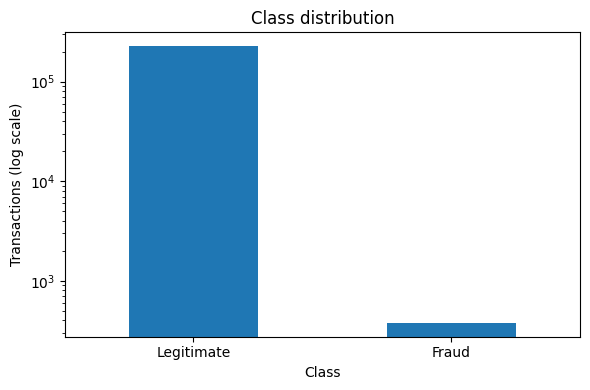

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
class_table["count"].plot(kind="bar", ax=ax)
ax.set_yscale("log")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class distribution")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


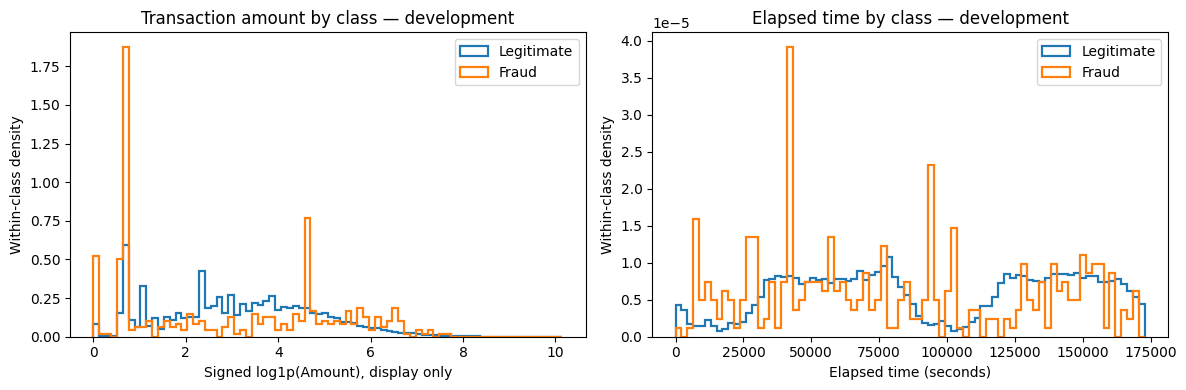

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in zip(axes, ["Amount", "Time"], ["Transaction amount", "Elapsed time"]):
    values_all = dev_df[column].to_numpy()
    # Display-only signed log1p makes the amount tail readable; model inputs are unchanged.
    if column == "Amount":
        values_all = np.sign(values_all) * np.log1p(np.abs(values_all))
    edges = np.histogram_bin_edges(values_all, bins=80)
    for label, name in [(0, "Legitimate"), (1, "Fraud")]:
        values = values_all[dev_df["Class"].to_numpy() == label]
        if len(values):
            ax.hist(values, bins=edges, density=True, histtype="step", linewidth=1.6, label=name)
    ax.set_title(f"{title} by class — development")
    ax.set_xlabel("Signed log1p(Amount), display only" if column == "Amount" else "Elapsed time (seconds)")
    ax.set_ylabel("Within-class density")
    ax.legend()
plt.tight_layout()
plt.show()

### Correlation context


In [10]:
target_corr = (
    dev_df[[*MODEL_FEATURES, "Time", "Class"]]
    .corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=np.abs, ascending=False)
)

target_corr.head(12).to_frame("correlation_with_Class")


,correlation_with_Class
V17,-0.313443
V14,-0.298425
V12,-0.252274
V10,-0.207367
V16,-0.187795
V3,-0.183757
V7,-0.170996
V11,0.151435
V4,0.129330
V18,-0.104708


The correlations are computed only on development data and are descriptive rather than causal. Because `V1`–`V28` are PCA components produced upstream, their near-orthogonality is expected and should not be interpreted as evidence that the raw confidential variables were independently related to fraud.


# Part I — Broad technical exploration


The following section is intentionally wider than the final candidate set. Its purpose is to demonstrate and test modelling choices, not to turn every algorithm into a production contender. All exploration remains inside the development partition.


## 7. Group-aware exploratory train/validation split


In [11]:
dev_group_table = (
    dev_df.groupby("feature_group", as_index=False)
          .agg(Class=("Class", "first"))
)
exp_train_groups, exp_val_groups = train_test_split(
    dev_group_table["feature_group"],
    test_size=0.20,
    stratify=dev_group_table["Class"],
    random_state=RANDOM_STATE + 1,
)
exp_val_group_set = set(exp_val_groups.tolist())

is_exp_val = dev_df["feature_group"].isin(exp_val_group_set)
exp_train_df = dev_df.loc[~is_exp_val].reset_index(drop=True)
exp_val_df = dev_df.loc[is_exp_val].reset_index(drop=True)

X_exp_train = exp_train_df[MODEL_FEATURES].copy()
y_exp_train = exp_train_df["Class"].astype(int).copy()
X_exp_val = exp_val_df[MODEL_FEATURES].copy()
y_exp_val = exp_val_df["Class"].astype(int).copy()

assert set(exp_train_df["feature_group"]).isdisjoint(set(exp_val_df["feature_group"]))

print({
    "exploration_train_rows": len(X_exp_train),
    "exploration_train_fraud": int(y_exp_train.sum()),
    "exploration_validation_rows": len(X_exp_val),
    "exploration_validation_fraud": int(y_exp_val.sum()),
})


{'exploration_train_rows': 181528, 'exploration_train_fraud': 302, 'exploration_validation_rows': 45502, 'exploration_validation_fraud': 76}


## 8. Min–Max scaling vs standardisation


In [12]:
minmax_scaler = MinMaxScaler().fit(X_exp_train)
standard_scaler = StandardScaler().fit(X_exp_train)

X_exp_train_minmax = minmax_scaler.transform(X_exp_train)
X_exp_val_minmax = minmax_scaler.transform(X_exp_val)
X_exp_train_std = standard_scaler.transform(X_exp_train)
X_exp_val_std = standard_scaler.transform(X_exp_val)

amount_idx = MODEL_FEATURES.index("Amount")
scaling_demo = pd.DataFrame({
    "representation": ["Original", "MinMax", "Standard"],
    "Amount mean": [
        X_exp_train["Amount"].mean(),
        X_exp_train_minmax[:, amount_idx].mean(),
        X_exp_train_std[:, amount_idx].mean(),
    ],
    "Amount std": [
        X_exp_train["Amount"].std(ddof=0),
        X_exp_train_minmax[:, amount_idx].std(ddof=0),
        X_exp_train_std[:, amount_idx].std(ddof=0),
    ],
})
scaling_demo


,representation,Amount mean,Amount std
0,Original,8.855609e+01,253.012965
1,MinMax,3.446948e-03,0.009848
2,Standard,6.262771e-18,1.000000


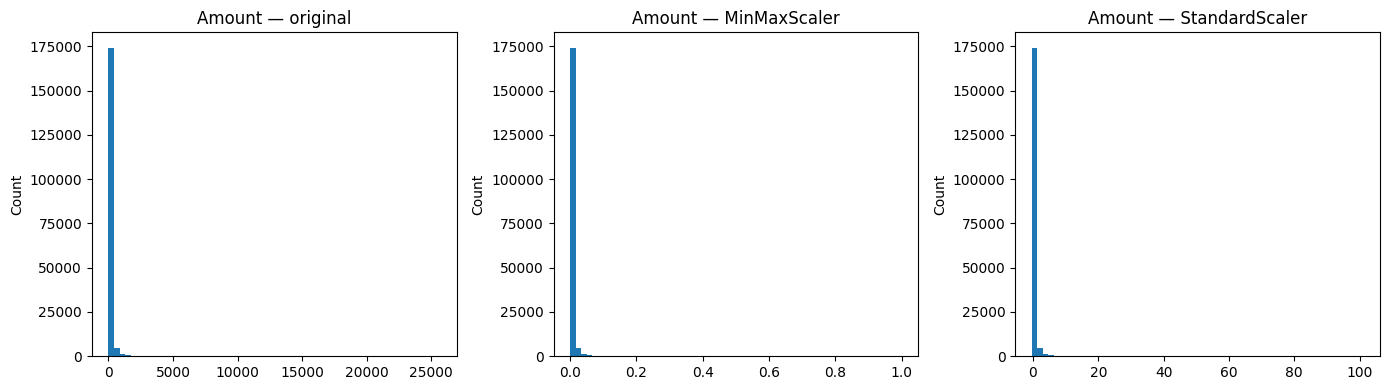

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(X_exp_train["Amount"], bins=60)
axes[0].set_title("Amount — original")
axes[1].hist(X_exp_train_minmax[:, amount_idx], bins=60)
axes[1].set_title("Amount — MinMaxScaler")
axes[2].hist(X_exp_train_std[:, amount_idx], bins=60)
axes[2].set_title("Amount — StandardScaler")
for ax in axes:
    ax.set_ylabel("Count")
# Each panel shows the complete training distribution on its own transformed scale.
plt.tight_layout()
plt.show()

Distance-based and gradient-based models benefit from explicit scaling; tree models do not require it. Standardisation is used for Logistic Regression, KNN and MLP. SMOTE is also applied in standardised space because its synthetic interpolation is distance-based.


## 9. Class-imbalance strategies


In [14]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)
ros = RandomOverSampler(random_state=RANDOM_STATE)
smote = SMOTE(random_state=RANDOM_STATE)

X_under, y_under = rus.fit_resample(X_exp_train_std, y_exp_train)
X_over, y_over = ros.fit_resample(X_exp_train_std, y_exp_train)
X_smote, y_smote = smote.fit_resample(X_exp_train_std, y_exp_train)

resampling_counts = pd.DataFrame({
    "Original": y_exp_train.value_counts().sort_index(),
    "Under-sampling": pd.Series(y_under).value_counts().sort_index(),
    "Over-sampling": pd.Series(y_over).value_counts().sort_index(),
    "SMOTE": pd.Series(y_smote).value_counts().sort_index(),
}).T.rename(columns={0: "Legitimate", 1: "Fraud"})

classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_exp_train)
class_weight_dict = dict(zip(classes, weights))
scale_pos_weight = float((y_exp_train == 0).sum() / (y_exp_train == 1).sum())

print("Balanced class weights:", class_weight_dict)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))
resampling_counts


Balanced class weights: {np.int64(0): np.float64(0.5008332137772725), np.int64(1): np.float64(300.5430463576159)}
XGBoost scale_pos_weight: 600.09


Class,Legitimate,Fraud
Original,181226,302
Under-sampling,302,302
Over-sampling,181226,181226
SMOTE,181226,181226


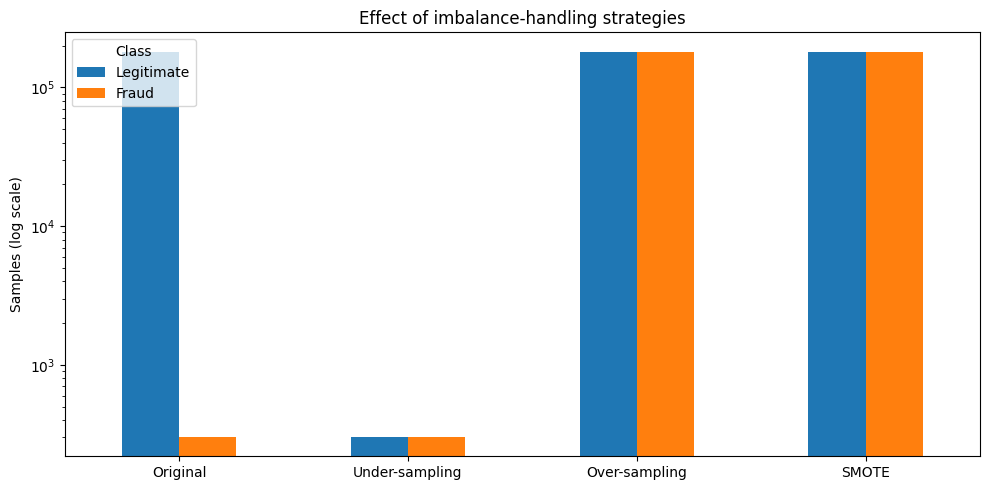

In [15]:
ax = resampling_counts.plot(kind="bar", figsize=(10, 5))
ax.set_yscale("log")
ax.set_ylabel("Samples (log scale)")
ax.set_title("Effect of imbalance-handling strategies")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Class")
plt.tight_layout()
plt.show()

Resampling and class weighting can alter score calibration even when ranking improves. Therefore the exploratory tables emphasise AP/ROC-AUC for ranking quality and report threshold metrics only as descriptive diagnostics. Final threshold selection is performed later from out-of-fold development scores.


## 10. Exploration helpers


In [16]:
def metrics_from_scores(y_true, scores, threshold=0.50):
    y_arr = np.asarray(y_true)
    s_arr = np.asarray(scores)
    pred = (s_arr >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_arr, pred, labels=[0, 1]).ravel()
    return {
        "AP": average_precision_score(y_arr, s_arr),
        "ROC-AUC": roc_auc_score(y_arr, s_arr),
        "Brier": brier_score_loss(y_arr, s_arr),
        "Precision@0.5": precision_score(y_arr, pred, zero_division=0),
        "Recall@0.5": recall_score(y_arr, pred, zero_division=0),
        "F1@0.5": f1_score(y_arr, pred, zero_division=0),
        "F2@0.5": fbeta_score(y_arr, pred, beta=2, zero_division=0),
        "FP@0.5": int(fp),
        "FN@0.5": int(fn),
        "TP@0.5": int(tp),
    }


def probability_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    raw = model.decision_function(X)
    # Monotonic mapping keeps AP/ROC ordering while giving a [0,1] diagnostic score.
    return 1 / (1 + np.exp(-raw))


def fit_score_sklearn(model, X_train_used, y_train_used, X_val_used, y_val_used, label):
    def compute():
        started = time.perf_counter()
        model.fit(X_train_used, y_train_used)
        fit_seconds = time.perf_counter() - started
        started = time.perf_counter()
        scores = probability_scores(model, X_val_used)
        predict_seconds = time.perf_counter() - started
        row = {"Experiment": label, "Fit seconds": fit_seconds, "Predict seconds": predict_seconds}
        row.update(metrics_from_scores(y_val_used, scores))
        return {"row": row, "scores": scores}
    payload = checkpointed("exploration", label, compute, validate=lambda p: valid_scores(p, len(y_val_used)))
    return payload["row"], None, payload["scores"]


def make_xgb(**extra_params):
    params = dict(
        n_estimators=XGB_ESTIMATORS,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device=XGB_DEVICE,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    params.update(extra_params)
    return XGBClassifier(**params)


## 11. Logistic Regression and imbalance handling


In [17]:
exploration_results = []
exploration_objects = {}

logistic_experiments = {
    "Logistic | Original": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        X_exp_train_std, y_exp_train,
    ),
    "Logistic | Class weights": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
        X_exp_train_std, y_exp_train,
    ),
    "Logistic | Under-sampling": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        X_under, y_under,
    ),
    "Logistic | Over-sampling": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        X_over, y_over,
    ),
    "Logistic | SMOTE": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        X_smote, y_smote,
    ),
}

for label, (model, Xtr, ytr) in logistic_experiments.items():
    row, fitted, scores = fit_score_sklearn(model, Xtr, ytr, X_exp_val_std, y_exp_val, label)
    exploration_results.append(row)
    exploration_objects[label] = {"scores": scores}

pd.DataFrame(exploration_results).sort_values("AP", ascending=False)


[REPLAYED] exploration / Logistic | Original


[REPLAYED] exploration / Logistic | Class weights


[REPLAYED] exploration / Logistic | Under-sampling


[REPLAYED] exploration / Logistic | Over-sampling


[REPLAYED] exploration / Logistic | SMOTE


,Experiment,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
0,Logistic | Original,1.180425,0.009307,0.740496,0.971927,0.000699,0.884615,0.605263,0.718750,0.646067,6,30,46
4,Logistic | SMOTE,1.930155,0.006213,0.700932,0.983370,0.024961,0.053864,0.907895,0.101695,0.217666,1212,7,69
1,Logistic | Class weights,1.569227,0.004052,0.700318,0.984786,0.022992,0.061082,0.921053,0.114566,0.241379,1076,6,70
3,Logistic | Over-sampling,2.261864,0.011525,0.691240,0.984863,0.023243,0.060606,0.921053,0.113729,0.239890,1085,6,70
2,Logistic | Under-sampling,0.009674,0.005763,0.523017,0.981783,0.032975,0.040204,0.934211,0.077090,0.171498,1695,5,71


## 12. KNN — useful baseline, expensive inference


In [18]:
# Full KNN inference against ~hundreds of thousands of stored training vectors is
# deliberately not used as a production-style benchmark. Under-sampling provides
# a tractable neighbourhood baseline while still demonstrating the model family.
knn_model = KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)
row, fitted, scores = fit_score_sklearn(
    knn_model, X_under, y_under, X_exp_val_std, y_exp_val, "KNN | Under-sampling"
)
exploration_results.append(row)
exploration_objects[row["Experiment"]] = {"scores": scores}
pd.DataFrame([row])


[REPLAYED] exploration / KNN | Under-sampling


,Experiment,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
0,KNN | Under-sampling,0.001416,0.074699,0.361507,0.966048,0.023167,0.058088,0.855263,0.108787,0.228391,1054,11,65


### Why kernel SVM is not exhaustively benchmarked

A kernel SVM was considered but is not trained on the full dataset. Exact nonlinear SVM training and inference scale poorly with the number of samples and support vectors, making an exhaustive full-data search a poor use of compute for ~285k rows. This is a **resource-aware modelling decision**, not an assumption that SVMs are invalid for fraud detection. Logistic Regression supplies a scalable linear baseline, while tree ensembles and neural models cover nonlinear alternatives. Approximate kernels or linear SVM variants would be reasonable follow-up experiments if SVM-specific performance were a project goal.


## 13. Decision Tree and Random Forest


In [19]:
tree_models = {
    "Decision Tree | Original": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    "Decision Tree | Class weights": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest | Original": RandomForestClassifier(
        n_estimators=RF_ESTIMATORS, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Random Forest | Class weights": RandomForestClassifier(
        n_estimators=RF_ESTIMATORS, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ),
}

for label, model in tree_models.items():
    row, fitted, scores = fit_score_sklearn(model, X_exp_train, y_exp_train, X_exp_val, y_exp_val, label)
    exploration_results.append(row)
    exploration_objects[label] = {"scores": scores}

# SMOTE is distance-based, so it is generated in standardised space; the tree then
# consumes the resulting standardised synthetic training representation.
rf_smote_explore = RandomForestClassifier(
    n_estimators=RF_ESTIMATORS, n_jobs=-1, random_state=RANDOM_STATE
)
row, fitted, scores = fit_score_sklearn(
    rf_smote_explore, X_smote, y_smote, X_exp_val_std, y_exp_val, "Random Forest | SMOTE"
)
exploration_results.append(row)
exploration_objects[row["Experiment"]] = {"scores": scores}

pd.DataFrame(exploration_results).query(
    "Experiment.str.contains('Tree|Random Forest')", engine="python"
).sort_values("AP", ascending=False)


[REPLAYED] exploration / Decision Tree | Original


[REPLAYED] exploration / Decision Tree | Class weights


[REPLAYED] exploration / Random Forest | Original


[REPLAYED] exploration / Random Forest | Class weights


[REPLAYED] exploration / Random Forest | SMOTE


,Experiment,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
9,Random Forest | Class weights,77.344611,0.207364,0.843303,0.957442,0.000445,0.981818,0.710526,0.824427,0.752089,1,22,54
10,Random Forest | SMOTE,261.609818,0.325981,0.838630,0.971960,0.000555,0.845070,0.789474,0.816327,0.800000,11,16,60
8,Random Forest | Original,146.634596,0.279364,0.826375,0.944294,0.000441,0.982456,0.736842,0.842105,0.775623,1,20,56
6,Decision Tree | Original,11.577597,0.004778,0.700593,0.872408,0.000582,0.888889,0.736842,0.805755,0.762943,7,20,56
7,Decision Tree | Class weights,11.986993,0.005958,0.520578,0.906690,0.005728,0.206667,0.815789,0.329787,0.513245,238,14,62


## 14. XGBoost


In [20]:
xgb_experiments = {
    "XGBoost | Original": (make_xgb(), X_exp_train, y_exp_train, X_exp_val),
    "XGBoost | Class weights": (
        make_xgb(scale_pos_weight=scale_pos_weight), X_exp_train, y_exp_train, X_exp_val
    ),
    "XGBoost | SMOTE": (make_xgb(), X_smote, y_smote, X_exp_val_std),
}

for label, (model, Xtr, ytr, Xval) in xgb_experiments.items():
    row, fitted, scores = fit_score_sklearn(model, Xtr, ytr, Xval, y_exp_val, label)
    exploration_results.append(row)
    exploration_objects[label] = {"scores": scores}

pd.DataFrame(exploration_results).query(
    "Experiment.str.startswith('XGBoost')", engine="python"
).sort_values("AP", ascending=False)


[REPLAYED] exploration / XGBoost | Original


[REPLAYED] exploration / XGBoost | Class weights


[REPLAYED] exploration / XGBoost | SMOTE


,Experiment,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
12,XGBoost | Class weights,3.590685,0.094704,0.840230,0.980294,0.000481,0.893939,0.776316,0.830986,0.797297,7,17,59
11,XGBoost | Original,6.893063,0.087546,0.834383,0.984655,0.000438,0.949153,0.736842,0.829630,0.771350,3,20,56
13,XGBoost | SMOTE,9.875536,0.095140,0.829914,0.982617,0.000690,0.734940,0.802632,0.767296,0.788114,22,15,61


## 15. `MLPClassifier`


In [21]:
mlp_variants = {
    "MLPClassifier | Original": (X_exp_train_std, y_exp_train),
    "MLPClassifier | SMOTE": (X_smote, y_smote),
}

for label, (Xtr, ytr) in mlp_variants.items():
    model = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        batch_size=1024,
        early_stopping=False,  # avoid accuracy-based internal early stopping on this rare-event task
        max_iter=15 if FAST_MODE else 140,
        random_state=RANDOM_STATE,
    )
    row, fitted, scores = fit_score_sklearn(model, Xtr, ytr, X_exp_val_std, y_exp_val, label)
    exploration_results.append(row)
    exploration_objects[label] = {"scores": scores}

pd.DataFrame(exploration_results).query(
    "Experiment.str.startswith('MLPClassifier')", engine="python"
).sort_values("AP", ascending=False)


[REPLAYED] exploration / MLPClassifier | Original


[REPLAYED] exploration / MLPClassifier | SMOTE


,Experiment,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
14,MLPClassifier | Original,32.186074,0.046294,0.846597,0.990146,0.000416,0.952381,0.789474,0.863309,0.817439,3,16,60
15,MLPClassifier | SMOTE,54.696100,0.027966,0.816292,0.973860,0.000559,0.840580,0.763158,0.800000,0.777480,11,18,58


## 16. Keras / TensorFlow — exploratory neural-network study


In [22]:
keras_results_df = pd.DataFrame()
keras_models = {}

if RUN_KERAS:
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    from tensorflow.keras.layers import BatchNormalization, Dense, Dropout, Input

    # Separate early-stopping data from the external exploration validation set.
    keras_group_table = (
        exp_train_df.groupby("feature_group", as_index=False)
                    .agg(Class=("Class", "first"))
    )
    keras_fit_groups, keras_es_groups = train_test_split(
        keras_group_table["feature_group"],
        test_size=0.15,
        stratify=keras_group_table["Class"],
        random_state=RANDOM_STATE + 2,
    )
    keras_es_set = set(keras_es_groups.tolist())
    keras_es_mask = exp_train_df["feature_group"].isin(keras_es_set)
    keras_fit_df = exp_train_df.loc[~keras_es_mask].reset_index(drop=True)
    keras_es_df = exp_train_df.loc[keras_es_mask].reset_index(drop=True)

    keras_scaler = StandardScaler().fit(keras_fit_df[MODEL_FEATURES])
    X_kfit = keras_scaler.transform(keras_fit_df[MODEL_FEATURES])
    y_kfit = keras_fit_df["Class"].astype(int).to_numpy()
    X_kes = keras_scaler.transform(keras_es_df[MODEL_FEATURES])
    y_kes = keras_es_df["Class"].astype(int).to_numpy()
    X_kexternal = keras_scaler.transform(X_exp_val)

    keras_weights_arr = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_kfit)
    keras_class_weight = dict(zip(np.array([0, 1]), keras_weights_arr))
    keras_smote = SMOTE(random_state=RANDOM_STATE)
    X_kfit_smote, y_kfit_smote = keras_smote.fit_resample(X_kfit, y_kfit)

    def build_keras_model(input_dim):
        model = Sequential([
            Input(shape=(input_dim,)),
            Dense(128, activation="relu"),
            BatchNormalization(),
            Dropout(0.25),
            Dense(64, activation="relu"),
            BatchNormalization(),
            Dropout(0.25),
            Dense(32, activation="relu"),
            Dropout(0.15),
            Dense(1, activation="sigmoid"),
        ])
        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=[
                tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
                tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            ],
        )
        return model

    keras_runs = {
        "Keras | Original": {"X": X_kfit, "y": y_kfit, "class_weight": None},
        "Keras | Class weights": {"X": X_kfit, "y": y_kfit, "class_weight": keras_class_weight},
        "Keras | SMOTE": {"X": X_kfit_smote, "y": y_kfit_smote, "class_weight": None},
    }

    keras_rows = []
    for label, cfg in keras_runs.items():
        def compute_keras():
            tf.keras.backend.clear_session()
            # Same seed for every strategy so the comparison does not confound strategy with initialisation.
            tf.keras.utils.set_random_seed(RANDOM_STATE)
            model = build_keras_model(X_kfit.shape[1])
            callbacks = [
                EarlyStopping(monitor="val_loss", patience=3 if FAST_MODE else 5, restore_best_weights=True),
                ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5, min_lr=1e-5),
            ]
            started = time.perf_counter()
            history = model.fit(
                cfg["X"], cfg["y"],
                validation_data=(X_kes, y_kes),
                epochs=6 if FAST_MODE else 30,
                batch_size=2048,
                class_weight=cfg["class_weight"],
                callbacks=callbacks,
                verbose=0,
                shuffle=True,
            )
            fit_seconds = time.perf_counter() - started
            started = time.perf_counter()
            scores = model.predict(X_kexternal, batch_size=4096, verbose=0).ravel()
            predict_seconds = time.perf_counter() - started
            row = {"Experiment": label, "Epochs": len(history.history["loss"]), "Fit seconds": fit_seconds, "Predict seconds": predict_seconds}
            row.update(metrics_from_scores(y_exp_val, scores))
            return {"row": row, "scores": scores, "history": history.history}
        payload = checkpointed("keras", label, compute_keras,
                               validate=lambda p: valid_scores(p, len(y_exp_val)))
        keras_rows.append(payload["row"])
        keras_models[label] = {"scores": payload["scores"], "history": payload["history"]}

    keras_results_df = pd.DataFrame(keras_rows).sort_values("AP", ascending=False).reset_index(drop=True)
    exploration_results.extend(keras_results_df.drop(columns=["Epochs"]).to_dict("records"))
    display(keras_results_df)
else:
    print("RUN_KERAS=0 — Keras exploration skipped.")


[REPLAYED] keras / Keras | Original


[REPLAYED] keras / Keras | Class weights


[REPLAYED] keras / Keras | SMOTE


,Experiment,Epochs,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
0,Keras | SMOTE,24,50.978699,0.302712,0.853777,0.976447,0.000626,0.794872,0.815789,0.805195,0.811518,16,14,62
1,Keras | Original,12,16.498330,0.287454,0.783504,0.944863,0.000586,0.868852,0.697368,0.773723,0.726027,8,23,53
2,Keras | Class weights,30,35.061633,0.280860,0.731330,0.976628,0.007166,0.147253,0.881579,0.252354,0.441370,388,9,67


### Keras threshold sensitivity — held-out development exploration partition only

In [23]:
keras_threshold_table = pd.DataFrame()
if RUN_KERAS and not keras_results_df.empty:
    best_keras_label = keras_results_df.iloc[0]["Experiment"]
    keras_scores = keras_models[best_keras_label]["scores"]
    threshold_rows = []
    for threshold in np.arange(0.10, 0.91, 0.10):
        row = {"Threshold": round(float(threshold), 2)}
        row.update(metrics_from_scores(y_exp_val, keras_scores, threshold=float(threshold)))
        threshold_rows.append(row)
    keras_threshold_table = pd.DataFrame(threshold_rows)
    # Only this table varies the threshold; fixed-0.5 exploration keys remain unchanged.
    keras_threshold_table = keras_threshold_table.rename(columns={
        key: key.removesuffix("@0.5") for key in keras_threshold_table.columns if key.endswith("@0.5")
    })
    print("Held-out development validation threshold sensitivity for:", best_keras_label)
    display(keras_threshold_table)
else:
    print("Keras threshold analysis skipped.")

Held-out development validation threshold sensitivity for: Keras | SMOTE


,Threshold,AP,ROC-AUC,Brier,Precision,Recall,F1,F2,FP,FN,TP
0,0.1,0.853777,0.976447,0.000626,0.750000,0.828947,0.787500,0.811856,21,13,63
1,0.2,0.853777,0.976447,0.000626,0.756098,0.815789,0.784810,0.803109,20,14,62
2,0.3,0.853777,0.976447,0.000626,0.765432,0.815789,0.789809,0.805195,19,14,62
3,0.4,0.853777,0.976447,0.000626,0.784810,0.815789,0.800000,0.809399,17,14,62
4,0.5,0.853777,0.976447,0.000626,0.794872,0.815789,0.805195,0.811518,16,14,62
5,0.6,0.853777,0.976447,0.000626,0.802632,0.802632,0.802632,0.802632,15,15,61
6,0.7,0.853777,0.976447,0.000626,0.802632,0.802632,0.802632,0.802632,15,15,61
7,0.8,0.853777,0.976447,0.000626,0.813333,0.802632,0.807947,0.804749,14,15,61
8,0.9,0.853777,0.976447,0.000626,0.810811,0.789474,0.800000,0.793651,14,16,60


Keras is intentionally **not** placed into the final nested-CV leaderboard. It remains a substantial exploratory experiment, but a single neural-network validation study is not statistically equivalent to the grouped nested-CV protocol used for the final sklearn/XGBoost candidates.

The Keras SMOTE variant led the single exploratory comparison (AP approximately 0.8538); it was not evaluated under the final grouped nested-CV protocol. Early stopping monitored validation loss, not AP. Neither that result nor the monitoring choice establishes superiority or inferiority under nested CV.

## 17. Exploratory leaderboard


In [24]:
exploration_df = (
    pd.DataFrame(exploration_results)
      .drop_duplicates(subset=["Experiment"], keep="last")
      .sort_values(["AP", "ROC-AUC"], ascending=False)
      .reset_index(drop=True)
)
exploration_df


,Experiment,Fit seconds,Predict seconds,AP,ROC-AUC,Brier,Precision@0.5,Recall@0.5,F1@0.5,F2@0.5,FP@0.5,FN@0.5,TP@0.5
0,Keras | SMOTE,50.978699,0.302712,0.853777,0.976447,0.000626,0.794872,0.815789,0.805195,0.811518,16,14,62
1,MLPClassifier | Original,32.186074,0.046294,0.846597,0.990146,0.000416,0.952381,0.789474,0.863309,0.817439,3,16,60
2,Random Forest | Class weights,77.344611,0.207364,0.843303,0.957442,0.000445,0.981818,0.710526,0.824427,0.752089,1,22,54
3,XGBoost | Class weights,3.590685,0.094704,0.840230,0.980294,0.000481,0.893939,0.776316,0.830986,0.797297,7,17,59
4,Random Forest | SMOTE,261.609818,0.325981,0.838630,0.971960,0.000555,0.845070,0.789474,0.816327,0.800000,11,16,60
5,XGBoost | Original,6.893063,0.087546,0.834383,0.984655,0.000438,0.949153,0.736842,0.829630,0.771350,3,20,56
6,XGBoost | SMOTE,9.875536,0.095140,0.829914,0.982617,0.000690,0.734940,0.802632,0.767296,0.788114,22,15,61
7,Random Forest | Original,146.634596,0.279364,0.826375,0.944294,0.000441,0.982456,0.736842,0.842105,0.775623,1,20,56
8,MLPClassifier | SMOTE,54.696100,0.027966,0.816292,0.973860,0.000559,0.840580,0.763158,0.800000,0.777480,11,18,58
9,Keras | Original,16.498330,0.287454,0.783504,0.944863,0.000586,0.868852,0.697368,0.773723,0.726027,8,23,53


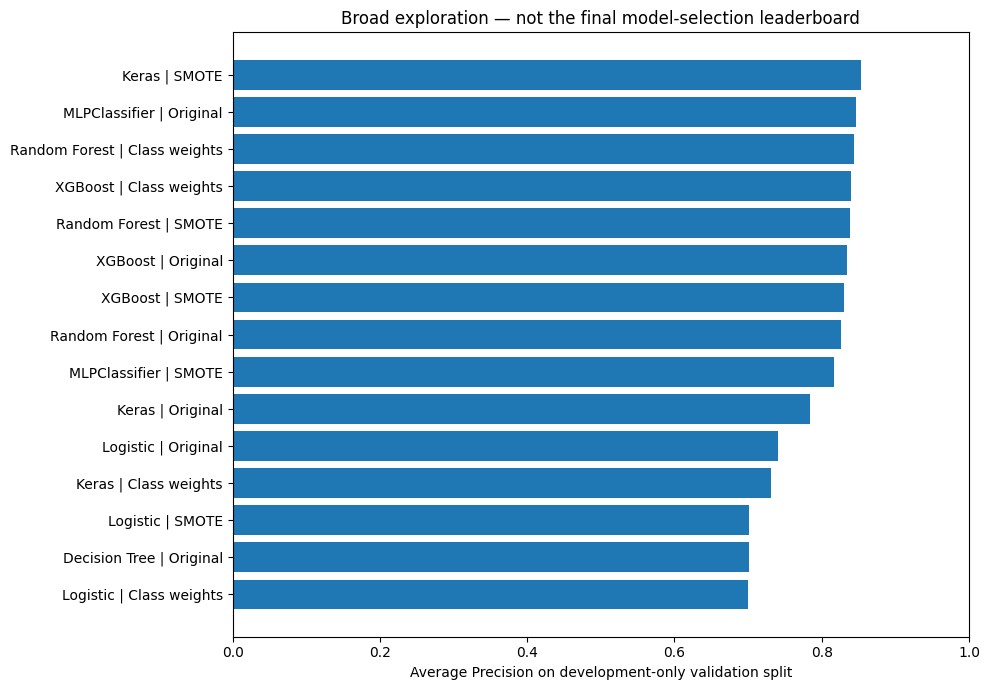

In [25]:
plot_df = exploration_df.head(15).sort_values("AP")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_df["Experiment"], plot_df["AP"])
ax.set_xlim(0, 1)
ax.set_xlabel("Average Precision on development-only validation split")
ax.set_title("Broad exploration — not the final model-selection leaderboard")
plt.tight_layout()
plt.show()


# Part II — Grouped nested model selection on development data


The final shortlist is deliberately smaller than the exploratory catalogue. It contains scalable baselines plus selected practical nonlinear families. Random Forest and XGBoost receive hyperparameter search; their out-of-fold predictions come from **nested** search, so outer validation labels cannot influence the hyperparameters used to score those rows.

The same feature-group constraint is enforced in both outer and inner folds.

## 18. Candidate definitions and compute-aware search spaces

The final shortlist stays intentionally smaller than the exploratory catalogue. Random Forest and XGBoost are tuned with **curated randomized search** rather than an artificially huge grid: the full run samples 10 configurations per search from deliberately narrowed, plausible regions. This is a compute-aware design choice, not a claim of exhaustive optimisation. Nested grouped CV compares the eight specified procedures in the full run, not all possible configurations or model families. The fixed XGBoost preset is not the library default and lies outside the tuned grid (for example, depth 6, 400 estimators and sampling fractions 0.85). The reference search sampled 10 of 48 Random Forest and 10 of 288 XGBoost configurations per inner search; these are unequal search fractions and computational budgets. Neural and resampling procedures are included as fixed candidates, not subjected to equivalent tuning.

The earlier public notebook used a different fixed XGBoost configuration (100 trees, depth 6, learning rate 0.1, sampling fractions 0.8; old cells 117, 129, 157 and 171); V5.1 uses 400/6/0.08/0.85. The precise historical motivation for every preset choice is not established. This is a retrospective comparison, not evidence of prospectively chosen parameters. The exploratory MLP uses 140 iterations, the shortlisted MLP 120; budgets are not harmonised.

In [26]:
def make_logistic():
    return SkPipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ])


def make_mlp():
    return SkPipeline([
        ("scale", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            batch_size=1024,
            early_stopping=False,
            max_iter=12 if FAST_MODE else 120,
            random_state=RANDOM_STATE,
        )),
    ])


def make_rf():
    return RandomForestClassifier(
        n_estimators=RF_ESTIMATORS,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )


def make_rf_smote():
    return ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(
            n_estimators=RF_ESTIMATORS,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ])

fixed_candidates = {
    "Dummy prior": DummyClassifier(strategy="prior"),
    "Logistic Regression": make_logistic(),
    "Random Forest": make_rf(),
    "XGBoost": make_xgb(),
}

# Extended grouped-CV checks keep the neural/resampling candidates visible in the
# full portfolio run without multiplying them through the inner tuning loop.
if RUN_EXTENDED_CV:
    fixed_candidates.update({
        "MLPClassifier": make_mlp(),
        "Random Forest + SMOTE": make_rf_smote(),
    })

# Curated, compute-aware search spaces. The goal is not to pretend to exhaust a
# combinatorial grid; it is to spend the search budget on plausible regions while
# nested CV protects the performance estimate.
rf_search_space = {
    "n_estimators": [300, 500],
    "max_depth": [None, 8, 12],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.7],
    "class_weight": [None, "balanced_subsample"],
}

xgb_search_space = {
    "n_estimators": [300, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.08],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3],
    "reg_lambda": [1.0, 5.0],
}

# Smoke-test mode validates control flow rather than reproducing the full search
# budget. Keep the same families/parameter names but cap estimator counts.
if FAST_MODE:
    rf_search_space = {
        **rf_search_space,
        "n_estimators": [RF_ESTIMATORS],
    }
    xgb_search_space = {
        **xgb_search_space,
        "n_estimators": [XGB_ESTIMATORS],
    }

tuned_candidates = {
    "Random Forest tuned": (make_rf(), rf_search_space),
    "XGBoost tuned": (make_xgb(), xgb_search_space),
}

print({
    "search_strategy": "compute-aware randomized search",
    "search_iterations_per_search": SEARCH_ITER,
    "rf_candidate_space_size": int(np.prod([len(v) for v in rf_search_space.values()])),
    "xgb_candidate_space_size": int(np.prod([len(v) for v in xgb_search_space.values()])),
})

{'search_strategy': 'compute-aware randomized search', 'search_iterations_per_search': 10, 'rf_candidate_space_size': 48, 'xgb_candidate_space_size': 288}


## 19. Nested out-of-fold predictions


In [27]:
outer_cv = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
candidate_names = [*fixed_candidates.keys(), *tuned_candidates.keys()]
oof_scores = {name: np.full(len(X_dev), np.nan, dtype=float) for name in candidate_names}
oof_fold_ids = np.full(len(X_dev), -1, dtype=int)
outer_fold_rows = []
nested_best_params = {name: [] for name in tuned_candidates}

for fold, (train_idx, val_idx) in enumerate(outer_cv.split(X_dev, y_dev, groups=groups_dev), start=1):
    oof_fold_ids[val_idx] = fold
    X_tr, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_tr, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
    g_tr = groups_dev.iloc[train_idx]
    assert set(g_tr).isdisjoint(set(groups_dev.iloc[val_idx]))
    fold_identity = index_digest(train_idx, val_idx)
    for name in candidate_names:
        tuned = name in tuned_candidates
        def compute_nested():
            if tuned:
                base_estimator, search_space = tuned_candidates[name]
                inner_cv = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True,
                                               random_state=RANDOM_STATE + 100 + fold)
                model = RandomizedSearchCV(estimator=clone(base_estimator), param_distributions=search_space,
                    n_iter=SEARCH_ITER, scoring="average_precision", cv=inner_cv,
                    random_state=RANDOM_STATE + fold, n_jobs=1, refit=True, verbose=0)
            else:
                model = clone(fixed_candidates[name])
            started = time.perf_counter()
            if tuned:
                model.fit(X_tr, y_tr, groups=g_tr)
            else:
                model.fit(X_tr, y_tr)
            fit_seconds = time.perf_counter() - started
            started = time.perf_counter()
            scores = probability_scores(model.best_estimator_ if tuned else model, X_val)
            predict_seconds = time.perf_counter() - started
            row = {"Fold": fold, "Model": name, "AP": average_precision_score(y_val, scores),
                   "ROC-AUC": roc_auc_score(y_val, scores), "Fit seconds": fit_seconds,
                   "Predict seconds": predict_seconds, "Tuned inside fold": tuned}
            return {"scores": scores, "row": row, "best_params": model.best_params_ if tuned else None}
        payload = checkpointed("nested", f"fold {fold}/{OUTER_FOLDS}: {name}", compute_nested,
                               identity=fold_identity, validate=lambda p: valid_scores(p, len(val_idx)))
        oof_scores[name][val_idx] = payload["scores"]
        outer_fold_rows.append(payload["row"])
        if tuned:
            nested_best_params[name].append(payload["best_params"])

assert (oof_fold_ids > 0).all(), "Every development row must belong to one outer fold."
for name, scores in oof_scores.items():
    assert np.isfinite(scores).all(), f"Missing OOF predictions for {name}"
outer_fold_df = pd.DataFrame(outer_fold_rows)
outer_fold_df


[REPLAYED] nested / fold 1/3: Dummy prior


[REPLAYED] nested / fold 1/3: Logistic Regression


[REPLAYED] nested / fold 1/3: Random Forest


[REPLAYED] nested / fold 1/3: XGBoost


[REPLAYED] nested / fold 1/3: MLPClassifier


[REPLAYED] nested / fold 1/3: Random Forest + SMOTE


... (15 outputs left out)

[REPLAYED] nested / fold 3/3: Random Forest + SMOTE


[REPLAYED] nested / fold 3/3: Random Forest tuned


[REPLAYED] nested / fold 3/3: XGBoost tuned


,Fold,Model,AP,ROC-AUC,Fit seconds,Predict seconds,Tuned inside fold
0,1,Dummy prior,0.001678,0.500000,0.012041,0.001712,False
1,1,Logistic Regression,0.717874,0.976201,0.762566,0.047676,False
2,1,Random Forest,0.821639,0.953577,111.300404,0.379441,False
3,1,XGBoost,0.828975,0.983013,6.075882,0.133402,False
4,1,MLPClassifier,0.822338,0.973244,17.927557,0.054517,False
5,1,Random Forest + SMOTE,0.814258,0.970384,196.299842,0.559025,False
6,1,Random Forest tuned,0.821440,0.953005,4947.815642,0.276885,True
7,1,XGBoost tuned,0.833120,0.979920,101.341543,0.170215,True
8,2,Dummy prior,0.001608,0.500000,0.012047,0.001637,False
9,2,Logistic Regression,0.743023,0.973515,0.824499,0.037884,False


## 20. Development leaderboard and tuning stability


In [28]:
leaderboard_rows = []
for name, scores in oof_scores.items():
    model_folds = outer_fold_df.loc[outer_fold_df["Model"] == name]
    leaderboard_rows.append({
        "Model": name,
        "OOF AP": average_precision_score(y_dev, scores),
        "Outer AP mean": model_folds["AP"].mean(),
        "Outer AP std": model_folds["AP"].std(ddof=1),
        "OOF ROC-AUC": roc_auc_score(y_dev, scores),
        "Outer ROC-AUC mean": model_folds["ROC-AUC"].mean(),
        "OOF Brier": brier_score_loss(y_dev, scores),
        "Total fit seconds": model_folds["Fit seconds"].sum(),
        "Predict seconds": model_folds["Predict seconds"].sum(),
    })

oof_results_df = (
    pd.DataFrame(leaderboard_rows)
      .sort_values(["Outer AP mean", "OOF AP", "OOF ROC-AUC"], ascending=False)
      .reset_index(drop=True)
)

oof_results_df

,Model,OOF AP,Outer AP mean,Outer AP std,OOF ROC-AUC,Outer ROC-AUC mean,OOF Brier,Total fit seconds,Predict seconds
0,XGBoost,0.844070,0.844360,0.014998,0.983854,0.983925,0.000392,11.973749,0.404429
1,XGBoost tuned,0.838543,0.841885,0.009843,0.980062,0.983736,0.000395,300.905286,0.396884
2,Random Forest,0.838724,0.839255,0.017065,0.958646,0.958740,0.000434,332.360251,1.103274
3,Random Forest tuned,0.836513,0.839139,0.018756,0.963493,0.967694,0.000440,13878.250159,1.193300
4,Random Forest + SMOTE,0.837096,0.837364,0.021051,0.976271,0.976321,0.000571,600.447674,1.448871
5,MLPClassifier,0.826985,0.832171,0.008595,0.972360,0.972439,0.000482,64.815439,0.177497
6,Logistic Regression,0.735130,0.735219,0.015046,0.974578,0.974867,0.000712,2.487258,0.127313
7,Dummy prior,0.001639,0.001665,0.000052,0.493245,0.500000,0.001662,0.036770,0.005091


In [29]:
for model_name, params in nested_best_params.items():
    print(f"\n{model_name} — best parameters by outer fold")
    for i, param_set in enumerate(params, start=1):
        print(f"  fold {i}: {param_set}")



Random Forest tuned — best parameters by outer fold
  fold 1: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced_subsample'}
  fold 2: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced_subsample'}
  fold 3: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': None}

XGBoost tuned — best parameters by outer fold
  fold 1: {'subsample': 1.0, 'reg_lambda': 1.0, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
  fold 2: {'subsample': 1.0, 'reg_lambda': 5.0, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.08, 'colsample_bytree': 0.8}
  fold 3: {'subsample': 0.8, 'reg_lambda': 1.0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


Selected hyperparameters varied across outer folds. Inner alternative-configuration scores are not available to establish landscape stability or equivalence.

The **primary development ranking is the mean Average Precision across outer folds**. Pooled OOF AP is retained as a secondary diagnostic, but it can combine scores produced by different tuned configurations and probability scales. This distinction matters especially for tuned model families.

Pooled ROC-AUC is likewise descriptive: fold-specific score scales (including differing dummy priors) can affect comparisons across folds. With shuffle enabled, scikit-learn 1.6.1 permutes group class-count rows without consistently permuting group identities. The resulting assignments behave effectively as group-random rather than reliably class-stratified; group disjointness is unaffected. Verified outer-fold positive supports were 127, 122 and 129; the threshold folds contained 126, 125 and 127 positives. Group disjointness was maintained. Changing the splitter implementation would create a different experiment.

Later splitter implementations can produce different folds under the same seed. Selecting the largest of eight development means introduces selection optimism; the retrospective holdout evaluates the selected procedure, not an independent prospective replication.

## 21. Paired uncertainty for the two leading development candidates


In [30]:
def paired_bootstrap_mean_fold_ap(
    y_true,
    scores_a,
    scores_b,
    fold_ids,
    groups,
    n_boot=500 if FAST_MODE else 2000,
    seed=RANDOM_STATE,
):
    """Bootstrap the mean outer-fold AP difference while resampling whole feature groups.

    This matches the unit used by the grouped CV and the leaderboard. It is a
    descriptive uncertainty analysis conditional on the already selected top two
    candidates, not a formal post-selection significance test.
    """
    rng = np.random.default_rng(seed)
    y_arr = np.asarray(y_true)
    a_arr = np.asarray(scores_a)
    b_arr = np.asarray(scores_b)
    fold_arr = np.asarray(fold_ids)
    group_arr = np.asarray(groups)

    unique_folds = np.unique(fold_arr)
    observed_fold_diffs = []
    fold_group_rows = {}

    for fold in unique_folds:
        fold_idx = np.flatnonzero(fold_arr == fold)
        fold_group_rows[fold] = grouped_row_index(group_arr[fold_idx], fold_idx)
        observed_fold_diffs.append(
            average_precision_score(y_arr[fold_idx], a_arr[fold_idx])
            - average_precision_score(y_arr[fold_idx], b_arr[fold_idx])
        )

    diffs = []
    for _ in range(n_boot):
        per_fold = []
        valid = True
        for fold in unique_folds:
            group_index = fold_group_rows[fold]
            fold_groups = group_index[0]
            sampled_groups = rng.choice(fold_groups, size=len(fold_groups), replace=True)
            idx = expand_group_draw(sampled_groups, group_index)
            if np.unique(y_arr[idx]).size < 2:
                valid = False
                break
            per_fold.append(
                average_precision_score(y_arr[idx], a_arr[idx])
                - average_precision_score(y_arr[idx], b_arr[idx])
            )
        if valid:
            diffs.append(float(np.mean(per_fold)))

    diffs = np.asarray(diffs, dtype=float)
    if len(diffs) == 0:
        raise RuntimeError("No valid grouped bootstrap resamples were produced.")

    return pd.Series({
        "Mean outer-fold AP difference": float(np.mean(observed_fold_diffs)),
        "95% CI lower": float(np.quantile(diffs, 0.025)),
        "95% CI upper": float(np.quantile(diffs, 0.975)),
        "Valid bootstrap draws": int(len(diffs)),
    })


top_two = oof_results_df.head(2)["Model"].tolist()
if len(top_two) == 2:
    paired_dev_uncertainty = checkpointed("bootstrap", "paired development AP",
        lambda: paired_bootstrap_mean_fold_ap(y_dev, oof_scores[top_two[0]], oof_scores[top_two[1]],
                                              oof_fold_ids, groups_dev), identity={"models": top_two, "scores": [hashlib.sha256(np.asarray(oof_scores[name]).tobytes()).hexdigest() for name in top_two]})
    display(pd.DataFrame({f"{top_two[0]} minus {top_two[1]}": paired_dev_uncertainty}))


[REPLAYED] bootstrap / paired development AP


,XGBoost minus XGBoost tuned
Mean outer-fold AP difference,0.002475
95% CI lower,-0.002697
95% CI upper,0.007092
Valid bootstrap draws,2000.000000


This bootstrap follows the same logic as the nested leaderboard: it estimates the difference in **mean outer-fold Average Precision**, rather than pooling probability scores from separately tuned folds. Within each fold, whole `feature_group` clusters are resampled so repeated model-input vectors remain dependent.

It is a **development-only, post-selection descriptive interval** for the two candidates that already ranked highest. It should not be interpreted as a formal hypothesis test proving one model is universally superior.

The resampling distribution is conditional on the existing fitted fold models, saved scores and splits, and does not include variability from refitting, selecting candidates, changing splits or unobserved entity dependence. An interval crossing zero establishes neither equivalence nor superiority.

## 22. Champion family selection

In [31]:
champion_name = oof_results_df.iloc[0]["Model"]
champion_nested_oof_scores = oof_scores[champion_name]
champion_outer_ap_mean = float(
    oof_results_df.loc[oof_results_df["Model"] == champion_name, "Outer AP mean"].iloc[0]
)

print("Development-selected model family:", champion_name)
print("Nested-CV outer AP mean:", round(champion_outer_ap_mean, 6))
print("Pooled nested OOF AP (secondary diagnostic):",
      round(average_precision_score(y_dev, champion_nested_oof_scores), 6))


Development-selected model family: XGBoost
Nested-CV outer AP mean: 0.84436
Pooled nested OOF AP (secondary diagnostic): 0.84407


In [32]:
# Threshold selection is intentionally deferred until the final hyperparameter
# configuration has been frozen. A threshold is configuration-dependent:
# nested OOF scores may mix different hyperparameters across outer folds.
print("Operating threshold: deferred until final configuration freeze.")


Operating threshold: deferred until final configuration freeze.


The nested grouped CV above provides the **development-only estimate for the specified candidate procedures**. It is not used directly to choose the benchmark operating threshold because a tuned family can select different hyperparameters in different outer folds.

The next stage freezes one development-only configuration, then generates a fresh set of grouped OOF predictions from **that exact configuration** solely for operating-point selection.

# Part III — Freeze the configuration and operating point, then unlock the holdout

## 23. Final development-only tuning and configuration freeze

In [33]:
final_best_params = None
final_search_seconds = 0.0

if champion_name in tuned_candidates:
    base_estimator, search_space = tuned_candidates[champion_name]
    final_inner_cv = StratifiedGroupKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + 999,
    )
    final_search = RandomizedSearchCV(
        estimator=clone(base_estimator),
        param_distributions=search_space,
        n_iter=SEARCH_ITER,
        scoring="average_precision",
        cv=final_inner_cv,
        random_state=RANDOM_STATE + 999,
        n_jobs=1,
        refit=True,
        verbose=0,
    )
    def compute_final_search():
        started = time.perf_counter()
        final_search.fit(X_dev, y_dev, groups=groups_dev)
        return {"params": final_search.best_params_, "seconds": time.perf_counter() - started}
    payload = checkpointed("final-search", champion_name, compute_final_search)
    final_search_seconds = payload["seconds"]
    final_best_params = payload["params"]
    frozen_template = clone(base_estimator).set_params(**final_best_params)
else:
    frozen_template = clone(fixed_candidates[champion_name])

print("Frozen model family:", champion_name)
print("Search iterations per tuned search:", SEARCH_ITER)
print("Final search performed:", final_best_params is not None)
print("Final development-only search seconds:", round(final_search_seconds, 2))
if final_best_params is not None:
    print("Frozen hyperparameters:", final_best_params)
else:
    print("Frozen hyperparameters: fixed candidate (no search)")

Frozen model family: XGBoost
Search iterations per tuned search: 10
Final search performed: False
Final development-only search seconds: 0.0
Frozen hyperparameters: fixed candidate (no search)


## 24. Operating-point selection for the frozen configuration

The hyperparameters are now frozen, but the model has **not** been evaluated on the holdout. A fresh grouped OOF pass produces scores from the exact configuration that will be refit and is used solely to choose the operating threshold and alert-budget view.

There is an important distinction: the frozen hyperparameters were selected using the development set before this cross-fitting pass. Therefore these scores are **development-only operating-point calibration scores, not an unbiased estimate of the complete selection pipeline**. The nested CV above estimates each specified procedure; the selected maximum is subject to selection optimism, and the frozen-within-V5.1 holdout remains the retrospective final evaluation.

In [34]:
threshold_cv = StratifiedGroupKFold(
    n_splits=OUTER_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE + 7,
)

final_config_oof_scores = np.full(len(X_dev), np.nan, dtype=float)
threshold_fold_rows = []

for fold, (train_idx, val_idx) in enumerate(
    threshold_cv.split(X_dev, y_dev, groups=groups_dev), start=1
):
    X_tr, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_tr, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
    g_tr = groups_dev.iloc[train_idx]
    g_val = groups_dev.iloc[val_idx]

    assert set(g_tr).isdisjoint(set(g_val))

    def compute_threshold_fold():
        model = clone(frozen_template)
        started = time.perf_counter()
        model.fit(X_tr, y_tr)
        fit_seconds = time.perf_counter() - started
        return {"scores": probability_scores(model, X_val), "seconds": fit_seconds}
    payload = checkpointed("threshold", f"{champion_name}: fold {fold}/{OUTER_FOLDS}",
                           compute_threshold_fold,
                           identity={"split": index_digest(train_idx, val_idx), "params": final_best_params},
                           validate=lambda p: valid_scores(p, len(val_idx)))
    scores, fit_seconds = payload["scores"], payload["seconds"]
    final_config_oof_scores[val_idx] = scores
    threshold_fold_rows.append({
        "Fold": fold,
        "AP": average_precision_score(y_val, scores),
        "ROC-AUC": roc_auc_score(y_val, scores),
        "Fit seconds": fit_seconds,
        "Fraud cases": int(y_val.sum()),
    })

assert np.isfinite(final_config_oof_scores).all()

threshold_fold_df = pd.DataFrame(threshold_fold_rows)
display(threshold_fold_df)
print("Frozen-config grouped OOF AP:",
      round(average_precision_score(y_dev, final_config_oof_scores), 6))


[REPLAYED] threshold / XGBoost: fold 1/3


[REPLAYED] threshold / XGBoost: fold 2/3


[REPLAYED] threshold / XGBoost: fold 3/3


,Fold,AP,ROC-AUC,Fit seconds,Fraud cases
0,1,0.876878,0.989266,2.932093,126
1,2,0.831834,0.976750,2.788109,125
2,3,0.821043,0.978794,2.947773,127


Frozen-config grouped OOF AP: 0.841902


In [35]:
precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_dev, final_config_oof_scores
)
precision_curve = precision_curve[:-1]
recall_curve = recall_curve[:-1]

f1_curve = (
    2 * precision_curve * recall_curve /
    np.clip(precision_curve + recall_curve, 1e-12, None)
)
f2_curve = (
    5 * precision_curve * recall_curve /
    np.clip(4 * precision_curve + recall_curve, 1e-12, None)
)

threshold_df = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_curve,
    "Recall": recall_curve,
    "F1": f1_curve,
    "F2": f2_curve,
})

best_threshold_row = threshold_df.loc[threshold_df["F2"].idxmax()]
selected_threshold = float(best_threshold_row["Threshold"])
selected_pred_oof = (final_config_oof_scores >= selected_threshold).astype(int)

print("Selected threshold for frozen configuration:", round(selected_threshold, 6))
display(best_threshold_row.to_frame("frozen_configuration_OOF"))


# Descriptive sensitivity after the frozen development-only operating point is selected.
near_optimal = threshold_df.loc[threshold_df["F2"] >= 0.99 * best_threshold_row["F2"]]
display(pd.Series({"Observed near-optimal candidates": len(near_optimal),
                   "Minimum observed threshold": near_optimal["Threshold"].min(),
                   "Maximum observed threshold": near_optimal["Threshold"].max()}).to_frame("Development sensitivity (not retuning)"))


Selected threshold for frozen configuration: 0.082783


,frozen_configuration_OOF
Threshold,0.082783
Precision,0.882857
Recall,0.817460
F1,0.848901
F2,0.829753


,Development sensitivity (not retuning)
Observed near-optimal candidates,68.000000
Minimum observed threshold,0.021027
Maximum observed threshold,0.179064


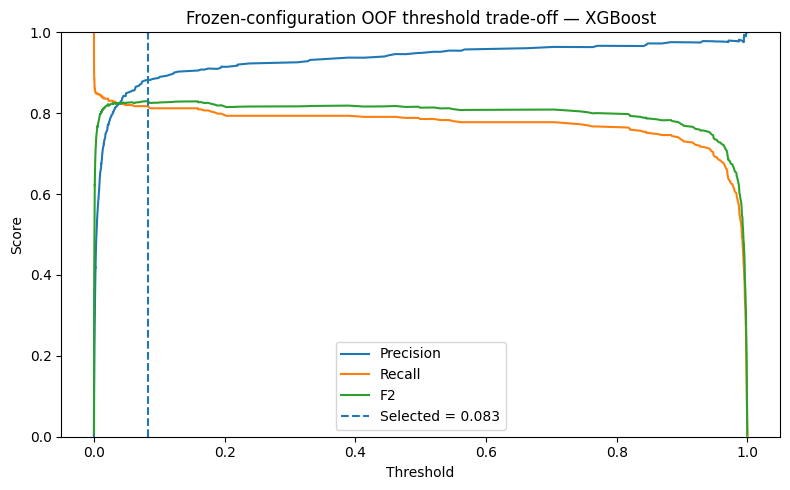

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
ax.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
ax.plot(threshold_df["Threshold"], threshold_df["F2"], label="F2")
ax.axvline(selected_threshold, linestyle="--", label=f"Selected = {selected_threshold:.3f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title(f"Frozen-configuration OOF threshold trade-off — {champion_name}")
ax.legend()
plt.tight_layout()
plt.show()


The threshold calculation is vectorised through the precision–recall curve. Threshold selection now corresponds to the **same frozen hyperparameter configuration** that will be refit for the benchmark, avoiding the mismatch that occurs when nested OOF predictions mix different tuned configurations.

F2 is a recall-weighted criterion, not a calibrated probability or a monetary cost function. In the reference run, the selected threshold was approximately 0.0827833. Saved-score sensitivity analysis found multiple near-optimal thresholds and substantial between-fold variation; it does not justify choosing a replacement using holdout scores.

The companion evidence supplement reports the 1,000 within-fold fingerprint-cluster bootstrap draws and individual fold optima for the frozen reference experiment. These are descriptive selection-sensitivity results, not a replacement operating point or an interval for refit variability.

## 25. Alert-budget view: Precision@k and Recall@k

In [37]:
def precision_recall_at_fraction(y_true, scores, fraction):
    y_arr = np.asarray(y_true)
    s_arr = np.asarray(scores, dtype=float)
    if y_arr.ndim != 1 or s_arr.ndim != 1 or y_arr.shape != s_arr.shape:
        raise ValueError("Labels and scores must be aligned one-dimensional arrays.")
    if not np.isin(y_arr, [0, 1]).all() or not np.isfinite(s_arr).all():
        raise ValueError("Expected binary labels and finite scores.")
    if not np.isfinite(fraction) or not 0 < fraction <= 1:
        raise ValueError("Review fraction must be in (0, 1].")
    if not len(y_arr):
        return 0, float("nan"), float("nan")
    n_alerts = max(1, int(np.ceil(len(y_arr) * fraction)))
    # Stable descending score order; ties retain original row order.
    order = np.argsort(-s_arr, kind="stable")
    selected = order[:n_alerts]
    tp = int(y_arr[selected].sum())
    positives = int(y_arr.sum())
    return n_alerts, tp / n_alerts, tp / positives if positives else float("nan")

budget_rows = []
for fraction in [0.001, 0.0025, 0.005, 0.01]:
    n_alerts, p_at_k, r_at_k = precision_recall_at_fraction(
        y_dev, final_config_oof_scores, fraction
    )
    budget_rows.append({
        "Alert fraction": fraction,
        "Alerts": n_alerts,
        "Precision@k": p_at_k,
        "Recall@k": r_at_k,
    })

alert_budget_df = pd.DataFrame(budget_rows)
alert_budget_df

,Alert fraction,Alerts,Precision@k,Recall@k
0,0.0010,228,0.978070,0.589947
1,0.0025,568,0.563380,0.846561
2,0.0050,1136,0.286092,0.859788
3,0.0100,2271,0.147512,0.886243


Precision@k / Recall@k avoids inventing financial costs that are not supplied with the public dataset. It answers an operational question directly: if an investigation team can review only the highest-scoring fraction of transactions, how concentrated are the fraud cases in that queue?

This is a retrospective batch-review capacity diagnostic, not an online alert-rate guarantee. Ties at a review-budget boundary need an explicit deterministic ordering rule.

## 26. Final refit on all development data

In [38]:
def compute_final_model():
    started = time.perf_counter()
    model = clone(frozen_template)
    model.fit(X_dev, y_dev)
    return {"model": model, "seconds": time.perf_counter() - started}

payload = checkpointed("final-refit", champion_name, compute_final_model, identity=final_best_params,
                       validate=lambda p: hasattr(p["model"], "predict_proba"))
final_model, final_fit_seconds = payload["model"], payload["seconds"]

print("Selected benchmark model:", champion_name)
print("Frozen threshold:", selected_threshold)
print("Final refit seconds:", round(final_fit_seconds, 2))
if final_best_params is not None:
    print("Frozen benchmark hyperparameters:", final_best_params)


[REPLAYED] final-refit / XGBoost


Selected benchmark model: XGBoost
Frozen threshold: 0.0827832967042923
Final refit seconds: 4.1


At this point the model family, hyperparameters and operating threshold are frozen using development data only. The test set is now unlocked for **reporting and diagnostics only**; no subsequent result is allowed to change the selected model, hyperparameters or threshold.

The freeze is a property of the revised protocol, not an assertion that the dataset was never inspected during earlier project versions.

## 27. Frozen holdout evaluation

In [39]:
started = time.perf_counter()
test_scores = probability_scores(final_model, X_test)
test_predict_seconds = time.perf_counter() - started
test_pred = (test_scores >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()

final_metrics = pd.Series({
    "Model": champion_name,
    "Threshold": selected_threshold,
    "Test rows": len(y_test),
    "Test fraud cases": int(y_test.sum()),
    "Test prevalence": float(y_test.mean()),
    "Average Precision": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "Brier score": brier_score_loss(y_test, test_scores),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "F2": fbeta_score(y_test, test_pred, beta=2, zero_division=0),
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    "Prediction seconds": test_predict_seconds,
})

final_metrics.to_frame("retrospective_holdout")


,retrospective_holdout
Model,XGBoost
Threshold,0.082783
Test rows,56696
Test fraud cases,95
Test prevalence,0.001676
Average Precision,0.862204
ROC-AUC,0.978001
Brier score,0.000406
Precision,0.88764
Recall,0.831579


### Frozen holdout alert-budget reporting

The same fractions specified during development are reported here without selecting a new operating point.

These are batch capacity summaries; the frozen classification threshold remains unchanged.

In [40]:
# Same pre-specified review fractions as development; report only after freeze.
holdout_budget_rows = []
for fraction in [0.001, 0.0025, 0.005, 0.01]:
    n_alerts, p_at_k, r_at_k = precision_recall_at_fraction(y_test, test_scores, fraction)
    holdout_budget_rows.append({"Alert fraction": fraction, "Alerts": n_alerts,
                                "Precision@k": p_at_k, "Recall@k": r_at_k})
holdout_alert_budget_df = pd.DataFrame(holdout_budget_rows)
holdout_alert_budget_df

,Alert fraction,Alerts,Precision@k,Recall@k
0,0.0010,57,1.000000,0.600000
1,0.0025,142,0.577465,0.863158
2,0.0050,284,0.295775,0.884211
3,0.0100,567,0.148148,0.884211


In [41]:
print(classification_report(y_test, test_pred, digits=4, zero_division=0))


              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56601
           1     0.8876    0.8316    0.8587        95

    accuracy                         0.9995     56696
   macro avg     0.9437    0.9157    0.9292     56696
weighted avg     0.9995    0.9995    0.9995     56696



## 28. Bootstrap confidence intervals

The intervals resample observed fingerprint clusters conditional on the frozen scores, model and threshold. They exclude refit, selection, split and hidden-entity uncertainty.

In [42]:
def grouped_bootstrap_metric_intervals(
    y_true,
    scores,
    groups,
    threshold,
    n_boot=400 if FAST_MODE else 2000,
    seed=RANDOM_STATE,
):
    """Bootstrap whole feature groups to preserve repeated-input dependence."""
    rng = np.random.default_rng(seed)
    y_arr = np.asarray(y_true)
    s_arr = np.asarray(scores)
    group_arr = np.asarray(groups)

    group_index = grouped_row_index(group_arr)
    unique_groups = group_index[0]
    rows = []

    for _ in range(n_boot):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        idx = expand_group_draw(sampled_groups, group_index)
        y_b, s_b = y_arr[idx], s_arr[idx]
        if np.unique(y_b).size < 2:
            continue
        p_b = (s_b >= threshold).astype(int)
        rows.append({
            "AP": average_precision_score(y_b, s_b),
            "ROC-AUC": roc_auc_score(y_b, s_b),
            "Precision": precision_score(y_b, p_b, zero_division=0),
            "Recall": recall_score(y_b, p_b, zero_division=0),
            "F1": f1_score(y_b, p_b, zero_division=0),
            "F2": fbeta_score(y_b, p_b, beta=2, zero_division=0),
        })

    boot = pd.DataFrame(rows)
    if boot.empty:
        raise RuntimeError("No valid grouped bootstrap resamples were produced.")

    pred = (s_arr >= threshold).astype(int)
    estimates = pd.Series({
        "AP": average_precision_score(y_arr, s_arr),
        "ROC-AUC": roc_auc_score(y_arr, s_arr),
        "Precision": precision_score(y_arr, pred, zero_division=0),
        "Recall": recall_score(y_arr, pred, zero_division=0),
        "F1": f1_score(y_arr, pred, zero_division=0),
        "F2": fbeta_score(y_arr, pred, beta=2, zero_division=0),
    })
    summary = pd.DataFrame({
        "estimate": estimates,
        "95% CI lower": boot.quantile(0.025),
        "95% CI upper": boot.quantile(0.975),
    })
    return summary, boot


bootstrap_summary, bootstrap_samples = checkpointed("bootstrap", "frozen test intervals",
    lambda: grouped_bootstrap_metric_intervals(y_test, test_scores, groups_test, selected_threshold),
    identity={"champion": champion_name, "threshold": selected_threshold, "scores": hashlib.sha256(np.asarray(test_scores).tobytes()).hexdigest()})
print(f"Valid bootstrap draws: {len(bootstrap_samples):,}")
print(f"Holdout fingerprint groups: {pd.Series(groups_test).nunique():,}; "
      f"positive groups: {pd.Series(np.asarray(groups_test)[np.asarray(y_test) == 1]).nunique():,}")
bootstrap_summary

[REPLAYED] bootstrap / frozen test intervals


Valid bootstrap draws: 2,000
Holdout fingerprint groups: 55,133; positive groups: 95


,estimate,95% CI lower,95% CI upper
AP,0.862204,0.791180,0.926337
ROC-AUC,0.978001,0.956279,0.994347
Precision,0.887640,0.816321,0.948992
Recall,0.831579,0.754861,0.905936
F1,0.858696,0.800000,0.909112
F2,0.842217,0.773088,0.903475


## 29. Final diagnostics: confusion matrix, PR, ROC and high-risk-tail calibration

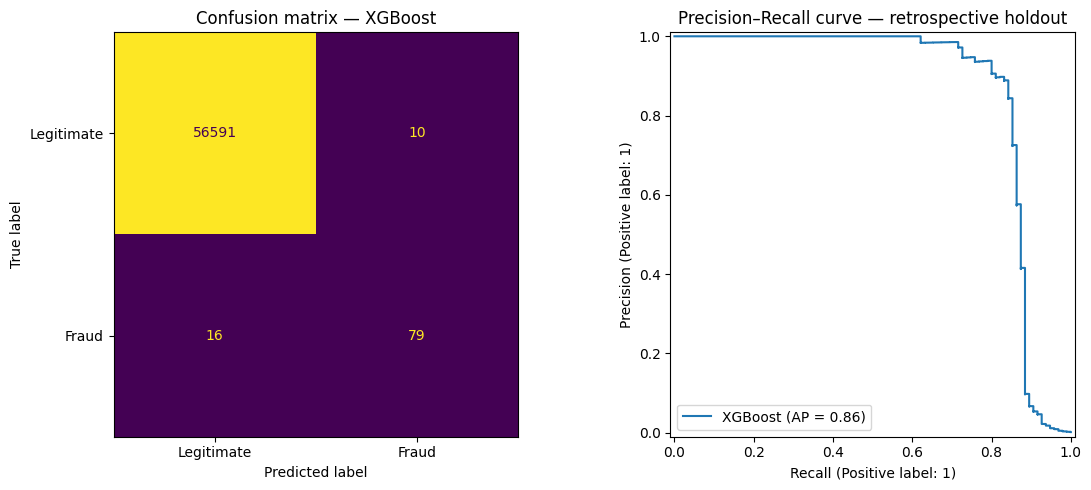

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Legitimate", "Fraud"], ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion matrix — {champion_name}")
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[1], name=champion_name)
axes[1].set_title("Precision–Recall curve — retrospective holdout")
plt.tight_layout()
plt.show()


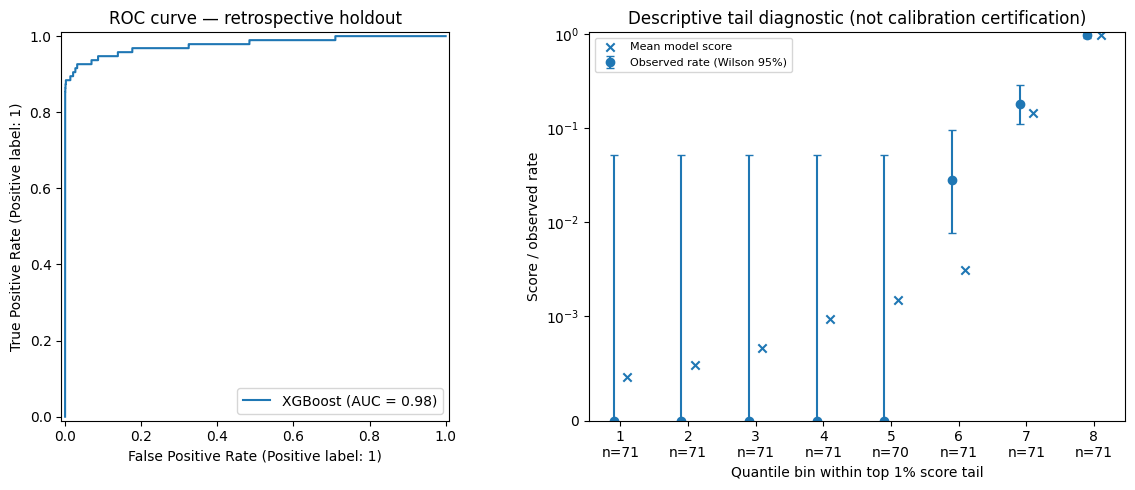

Tail cutoff: 0.000376 | rows: 567 | frauds: 84


,Mean predicted probability,Observed fraud rate,Transactions,Fraud cases
0,0.000416,0.000000,71,0
1,0.000528,0.000000,71,0
2,0.000694,0.000000,71,0
3,0.000969,0.000000,71,0
4,0.001481,0.000000,70,0
5,0.003062,0.028169,71,2
6,0.146243,0.183099,71,13
7,0.990508,0.971831,71,69


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[0], name=champion_name)
axes[0].set_title("ROC curve — retrospective holdout")

# Global deciles are nearly uninformative at ~0.17% prevalence. Inspect the
# operationally relevant high-score tail instead.
TAIL_FRACTION = 0.01
tail_cutoff = float(np.quantile(test_scores, 1 - TAIL_FRACTION))
tail_mask = np.asarray(test_scores) >= tail_cutoff
tail_y = np.asarray(y_test)[tail_mask]
tail_scores = np.asarray(test_scores)[tail_mask]

tail_n_bins = min(8, max(2, len(tail_scores) // 50))
tail_prob_true, tail_prob_pred = calibration_curve(
    tail_y, tail_scores, n_bins=tail_n_bins, strategy="quantile",
)
# Same quantile edges and boundary convention as calibration_curve; omit empty bins.
tail_edges = np.percentile(tail_scores, np.linspace(0, 100, tail_n_bins + 1))
tail_bin_ids = np.searchsorted(tail_edges[1:-1], tail_scores)
tail_support = np.bincount(tail_bin_ids, minlength=tail_n_bins)
tail_positive = np.bincount(tail_bin_ids, weights=tail_y, minlength=tail_n_bins)
tail_score_sum = np.bincount(tail_bin_ids, weights=tail_scores, minlength=tail_n_bins)
tail_nonempty = tail_support > 0
assert np.allclose(tail_prob_true, tail_positive[tail_nonempty] / tail_support[tail_nonempty])
assert np.allclose(tail_prob_pred, tail_score_sum[tail_nonempty] / tail_support[tail_nonempty])

# Plot bins separately, with no line implying behaviour between observed bins.
counts = tail_support[tail_nonempty]
observed = tail_prob_true
z = 1.959963984540054
centre = (observed + z*z/(2*counts)) / (1 + z*z/counts)
half = z*np.sqrt(observed*(1-observed)/counts + z*z/(4*counts*counts)) / (1 + z*z/counts)
lower, upper = np.maximum(0, centre-half), np.minimum(1, centre+half)
positions = np.arange(len(counts))
axes[1].errorbar(positions-0.10, observed, yerr=[np.maximum(0, observed-lower), np.maximum(0, upper-observed)], fmt="o", capsize=3, label="Observed rate (Wilson 95%)")
axes[1].scatter(positions+0.10, tail_prob_pred, marker="x", label="Mean model score")
axes[1].set_xticks(positions, [f"{i+1}\nn={m}" for i,m in enumerate(counts)])
axes[1].set_yscale("symlog", linthresh=0.001)
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Quantile bin within top 1% score tail")
axes[1].set_ylabel("Score / observed rate")
axes[1].set_title("Descriptive tail diagnostic (not calibration certification)")
axes[1].legend(fontsize=8)
# Wilson intervals are illustrative row-binomial intervals, not group-bootstrap CIs.

plt.tight_layout()
plt.show()

tail_calibration_df = pd.DataFrame({
    "Mean predicted probability": tail_prob_pred,
    "Observed fraud rate": tail_prob_true,
    "Transactions": tail_support[tail_nonempty],
    "Fraud cases": tail_positive[tail_nonempty].astype(int),
})
print(f"Tail cutoff: {tail_cutoff:.6f} | rows: {tail_mask.sum():,} | frauds: {int(tail_y.sum())}")
display(tail_calibration_df)

Calibration is reported as a diagnostic, not as the model-selection target. With fraud prevalence near 0.17%, global equal-frequency deciles collapse visually near the origin and hide the region where decisions are actually made. The plot therefore focuses on the **top 1% score tail**, while the Brier score remains a global summary.

This tail view is still diagnostic rather than a calibration procedure. If calibrated fraud probabilities were a product requirement, calibration would need to be fitted using development data only and validated on a separate partition.

Quantile bins in the selected tail have small supports. Observed rates are descriptive and conditioned on the score-tail selection; they do not demonstrate global calibration or quantify uncertainty from training. The underlying model scores should not be treated as calibrated production probabilities.

The per-bin Wilson intervals are descriptive row-binomial intervals, not clustered confidence intervals; they do not account for dependence among fingerprints or selection of the high-score tail. No interpolating line or calibrated-probability guarantee is implied.

## 30. Error analysis

In [45]:
error_df = test_df[["Time", "Amount", "Class"]].copy()
error_df["score"] = test_scores
error_df["prediction"] = test_pred
error_df["error_type"] = np.select(
    [
        (error_df["Class"] == 1) & (error_df["prediction"] == 0),
        (error_df["Class"] == 0) & (error_df["prediction"] == 1),
        (error_df["Class"] == 1) & (error_df["prediction"] == 1),
    ],
    ["False negative", "False positive", "True positive"],
    default="True negative",
)

error_summary = error_df.groupby("error_type").agg(
    rows=("Class", "size"),
    median_amount=("Amount", "median"),
    median_score=("score", "median"),
    min_score=("score", "min"),
    max_score=("score", "max"),
).sort_values("rows", ascending=False)
error_summary


,rows,median_amount,median_score,min_score,max_score
error_type,,,,,
True negative,56591,21.480,0.000001,7.175687e-09,0.057316
True positive,79,7.530,0.997410,1.229424e-01,0.999912
False negative,16,7.085,0.000077,4.489563e-07,0.058489
False positive,10,2.345,0.603539,9.221360e-02,0.982996


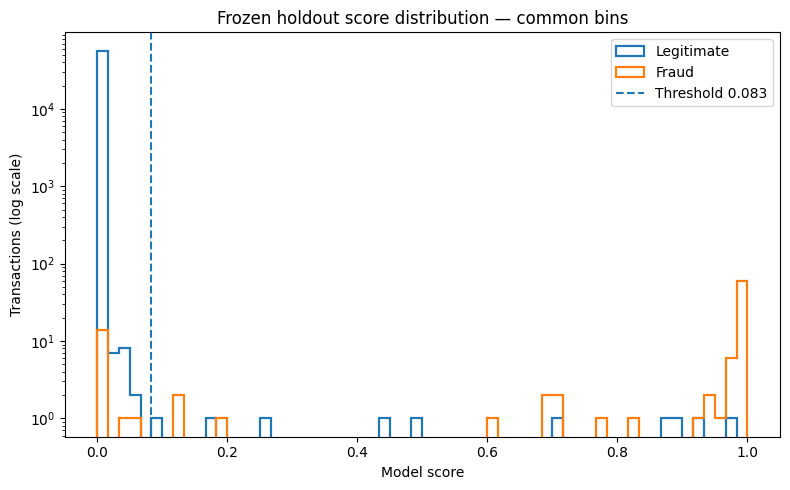

In [46]:
fig, ax = plt.subplots(figsize=(8, 5))
shared_score_edges = np.linspace(0, 1, 61)
for label, name in [(0, "Legitimate"), (1, "Fraud")]:
    ax.hist(test_scores[np.asarray(y_test) == label], bins=shared_score_edges,
            histtype="step", linewidth=1.6, label=name)
ax.axvline(selected_threshold, linestyle="--", label=f"Threshold {selected_threshold:.3f}")
ax.set_yscale("log")
ax.set_xlabel("Model score")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Frozen holdout score distribution — common bins")
ax.legend()
plt.tight_layout()
plt.show()

## 31. Permutation importance on the full retrospective holdout set

In [47]:
perm = checkpointed("diagnostics", "holdout permutation importance",
    lambda: permutation_importance(final_model, X_test, y_test, scoring="average_precision",
        n_repeats=1 if FAST_MODE else 6, random_state=RANDOM_STATE, n_jobs=1),
    identity={"champion": champion_name, "params": final_best_params})

importance_df = (
    pd.DataFrame({
        "Feature": MODEL_FEATURES,
        "Importance mean": perm.importances_mean,
        "Importance std": perm.importances_std,
    })
    .sort_values("Importance mean", ascending=False)
    .head(12)
)
importance_df


[REPLAYED] diagnostics / holdout permutation importance


,Feature,Importance mean,Importance std
13,V14,0.101477,0.009111
3,V4,0.032704,0.006441
28,Amount,0.013928,0.005339
11,V12,0.010099,0.002998
27,V28,0.008260,0.002461
6,V7,0.007110,0.002815
9,V10,0.005538,0.002497
15,V16,0.005436,0.001566
25,V26,0.004792,0.004186
10,V11,0.004125,0.002041


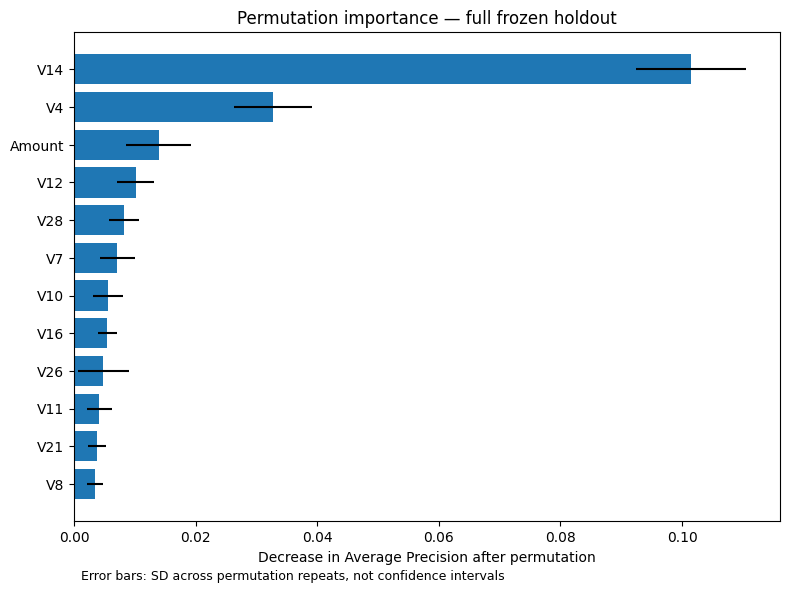

In [48]:
plot_imp = importance_df.sort_values("Importance mean")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_imp["Feature"], plot_imp["Importance mean"], xerr=plot_imp["Importance std"])
ax.set_xlabel("Decrease in Average Precision after permutation")
ax.set_title("Permutation importance — full frozen holdout")
ax.text(0.01, -0.12, "Error bars: SD across permutation repeats, not confidence intervals",
        transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

Permutation importance is **predictive, not causal**. The anonymised PCA-derived features also limit semantic interpretation: importance can identify which supplied components matter to this model, but not what underlying real-world customer behaviour caused fraud.

The plotted error bars are standard deviations across permutation repeats (six in the full reference run), not confidence intervals or causal effects.

# Part IV — Separate chronological robustness protocol

The chronological experiment shares the public dataset with the grouped random-split protocol and is not independent external validation. Six fixed candidates (excluding the two tuned searches) are compared on past training/validation only. The model and threshold are selected on past data, then the selected configuration is refitted on the full chronological past. Timestamp windows are disjoint; evaluation excludes feature fingerprints already present in the relevant history. The original run displayed aggregate future support before the freeze. This version masks the future fraud count and rate in the pre-freeze split table; this is not prospective blinding of an analyst who has already seen dataset totals or IID results. No future labels feed into temporal model or threshold selection. Post-freeze reporting computes the full-window comparison and exact cohort intersections.

## 32. Build strict past / validation / future windows

In [49]:
time_df = df.sort_values("Time", kind="stable").reset_index(drop=True).copy()

# Choose cut points from row quantiles but split by timestamp values, not row
# positions. This guarantees a timestamp cannot straddle train/validation/future.
train_time_cut = float(time_df["Time"].quantile(0.60, interpolation="higher"))
future_time_cut = float(time_df["Time"].quantile(0.80, interpolation="higher"))
assert train_time_cut < future_time_cut

t_train = time_df.loc[time_df["Time"] < train_time_cut].copy().reset_index(drop=True)
t_val = time_df.loc[
    (time_df["Time"] >= train_time_cut) & (time_df["Time"] < future_time_cut)
].copy().reset_index(drop=True)
t_future = time_df.loc[time_df["Time"] >= future_time_cut].copy().reset_index(drop=True)

assert len(t_train) and len(t_val) and len(t_future)
assert t_train["Time"].max() < t_val["Time"].min()
assert t_val["Time"].max() < t_future["Time"].min()

# Strict overlap control: validation vectors seen in temporal training and future
# vectors seen anywhere in the past are removed from the evaluation windows.
train_groups_time = set(t_train["feature_group"])
val_before = len(t_val)
t_val = t_val.loc[~t_val["feature_group"].isin(train_groups_time)].reset_index(drop=True)

past80_df = time_df.loc[time_df["Time"] < future_time_cut].copy()
past_groups_time = set(past80_df["feature_group"])
future_before = len(t_future)
t_future = t_future.loc[~t_future["feature_group"].isin(past_groups_time)].reset_index(drop=True)

# Removing overlaps cannot weaken the strict chronology.
assert t_train["Time"].max() < t_val["Time"].min()
assert t_val["Time"].max() < t_future["Time"].min()

temporal_split_summary = pd.DataFrame({
    "rows": [len(t_train), len(t_val), len(t_future)],
    "fraud": [int(t_train["Class"].sum()), int(t_val["Class"].sum()), None],
    "fraud_rate": [t_train["Class"].mean(), t_val["Class"].mean(), None],
    "time_min": [t_train["Time"].min(), t_val["Time"].min(), t_future["Time"].min()],
    "time_max": [t_train["Time"].max(), t_val["Time"].max(), t_future["Time"].max()],
}, index=["Past train (~0–60%)", "Past validation (~60–80%)", "Future test (~80–100%)"])

print(f"Timestamp cuts: train/validation={train_time_cut:g}, validation/future={future_time_cut:g}")
print(f"Temporal validation rows removed for feature overlap with train: {val_before - len(t_val):,}")
print(f"Future rows removed for feature overlap with earlier history: {future_before - len(t_future):,}")
temporal_split_summary

Timestamp cuts: train/validation=120393, validation/future=145234
Temporal validation rows removed for feature overlap with train: 561
Future rows removed for feature overlap with earlier history: 1,720


,rows,fraud,fraud_rate,time_min,time_max
Past train (~0–60%),170235,342.0,0.002009,0.0,120392.0
Past validation (~60–80%),56184,57.0,0.001015,120393.0,145233.0
Future test (~80–100%),55026,NaN,NaN,145234.0,172792.0


## 33. Past-only model selection

In [50]:
temporal_candidates = {
    "Dummy prior": DummyClassifier(strategy="prior"),
    "Logistic Regression": make_logistic(),
    "Random Forest": make_rf(),
    "XGBoost": make_xgb(),
}
if RUN_EXTENDED_CV:
    temporal_candidates.update({
        "MLPClassifier": make_mlp(),
        "Random Forest + SMOTE": make_rf_smote(),
    })

X_ttrain, y_ttrain = t_train[MODEL_FEATURES], t_train["Class"].astype(int)
X_tval, y_tval = t_val[MODEL_FEATURES], t_val["Class"].astype(int)
X_tfuture = t_future[MODEL_FEATURES]

temporal_val_scores = {}
temporal_rows = []
for name, template in temporal_candidates.items():
    def compute_temporal_candidate():
        model = clone(template)
        started = time.perf_counter()
        model.fit(X_ttrain, y_ttrain)
        fit_seconds = time.perf_counter() - started
        return {"scores": probability_scores(model, X_tval), "seconds": fit_seconds}
    payload = checkpointed("temporal-selection", name, compute_temporal_candidate,
                           validate=lambda p: valid_scores(p, len(y_tval)))
    scores, fit_seconds = payload["scores"], payload["seconds"]
    temporal_val_scores[name] = scores
    temporal_rows.append({
        "Model": name,
        "Validation AP": average_precision_score(y_tval, scores),
        "Validation ROC-AUC": roc_auc_score(y_tval, scores),
        "Fit seconds": fit_seconds,
    })

temporal_selection_df = (
    pd.DataFrame(temporal_rows)
      .sort_values("Validation AP", ascending=False)
      .reset_index(drop=True)
)
temporal_selection_df

[REPLAYED] temporal-selection / Dummy prior


[REPLAYED] temporal-selection / Logistic Regression


[REPLAYED] temporal-selection / Random Forest


[REPLAYED] temporal-selection / XGBoost


[REPLAYED] temporal-selection / MLPClassifier


[REPLAYED] temporal-selection / Random Forest + SMOTE


,Model,Validation AP,Validation ROC-AUC,Fit seconds
0,XGBoost,0.784754,0.982446,3.005696
1,Random Forest,0.775467,0.940913,120.420599
2,Random Forest + SMOTE,0.754620,0.971416,233.623709
3,MLPClassifier,0.749146,0.941591,27.215141
4,Logistic Regression,0.643344,0.968449,1.011148
5,Dummy prior,0.001015,0.500000,0.013107


## 34. Freeze temporal model and threshold, then evaluate the future

In [51]:
temporal_champion_name = temporal_selection_df.iloc[0]["Model"]
temporal_val_champion_scores = temporal_val_scores[temporal_champion_name]

p_t, r_t, thr_t = precision_recall_curve(y_tval, temporal_val_champion_scores)
p_t, r_t = p_t[:-1], r_t[:-1]
f2_t = 5 * p_t * r_t / np.clip(4 * p_t + r_t, 1e-12, None)
temporal_threshold = float(thr_t[np.nanargmax(f2_t)])

# Refit only after model family and threshold are frozen, using all history strictly before the future cut.
t_past80 = time_df.loc[time_df["Time"] < future_time_cut].copy()
def compute_temporal_final():
    model = clone(temporal_candidates[temporal_champion_name])
    model.fit(t_past80[MODEL_FEATURES], t_past80["Class"].astype(int))
    return {"model": model}
temporal_final_model = checkpointed("temporal-refit", temporal_champion_name, compute_temporal_final,
                                    validate=lambda p: hasattr(p["model"], "predict_proba"))["model"]

# Model family, configuration and threshold are frozen; future labels may now be disclosed.
y_tfuture = t_future["Class"].astype(int)
future_raw_y = time_df.loc[time_df["Time"] >= future_time_cut, "Class"].astype(int)
print("Future cohort support (raw / excluded / retained):",
      {"rows": [len(future_raw_y), len(future_raw_y) - len(y_tfuture), len(y_tfuture)],
       "frauds": [int(future_raw_y.sum()), int(future_raw_y.sum() - y_tfuture.sum()), int(y_tfuture.sum())]})
future_scores = probability_scores(temporal_final_model, X_tfuture)
future_pred = (future_scores >= temporal_threshold).astype(int)

temporal_metrics = pd.Series({
    "Model": temporal_champion_name,
    "Threshold": temporal_threshold,
    "Future rows": len(y_tfuture),
    "Future fraud cases": int(y_tfuture.sum()),
    "Future prevalence": float(y_tfuture.mean()),
    "Average Precision": average_precision_score(y_tfuture, future_scores),
    "ROC-AUC": roc_auc_score(y_tfuture, future_scores),
    "Precision": precision_score(y_tfuture, future_pred, zero_division=0),
    "Recall": recall_score(y_tfuture, future_pred, zero_division=0),
    "F1": f1_score(y_tfuture, future_pred, zero_division=0),
    "F2": fbeta_score(y_tfuture, future_pred, beta=2, zero_division=0),
})

temporal_metrics.to_frame("chronological_future_unseen_fingerprints")

[REPLAYED] temporal-refit / XGBoost


Future cohort support (raw / excluded / retained): {'rows': [56746, 1720, 55026], 'frauds': [74, 0, 74]}


,chronological_future_unseen_fingerprints
Model,XGBoost
Threshold,0.415831
Future rows,55026
Future fraud cases,74
Future prevalence,0.001345
Average Precision,0.79607
ROC-AUC,0.983969
Precision,0.932203
Recall,0.743243
F1,0.827068


## 35. Random holdout vs chronological future — descriptive comparison

In [52]:
comparison_df = pd.DataFrame({
    "Frozen grouped IID holdout": {
        "Prevalence": float(y_test.mean()),
        "Average Precision": average_precision_score(y_test, test_scores),
        "ROC-AUC": roc_auc_score(y_test, test_scores),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F2": fbeta_score(y_test, test_pred, beta=2, zero_division=0),
    },
    "Chronological future (unseen fingerprints)": {
        "Prevalence": float(y_tfuture.mean()),
        "Average Precision": average_precision_score(y_tfuture, future_scores),
        "ROC-AUC": roc_auc_score(y_tfuture, future_scores),
        "Precision": precision_score(y_tfuture, future_pred, zero_division=0),
        "Recall": recall_score(y_tfuture, future_pred, zero_division=0),
        "F2": fbeta_score(y_tfuture, future_pred, beta=2, zero_division=0),
    },
})
comparison_df

# Additional retrospective full-stream diagnostic; no change to the frozen model or threshold.
full_future = time_df.loc[time_df["Time"] >= future_time_cut]
full_future_y = full_future["Class"].astype(int)
full_future_scores = probability_scores(temporal_final_model, full_future[MODEL_FEATURES])
full_future_pred = (full_future_scores >= temporal_threshold).astype(int)
comparison_df["Chronological future (full window)"] = {
    "Prevalence": float(full_future_y.mean()),
    "Average Precision": average_precision_score(full_future_y, full_future_scores),
    "ROC-AUC": roc_auc_score(full_future_y, full_future_scores),
    "Precision": precision_score(full_future_y, full_future_pred, zero_division=0),
    "Recall": recall_score(full_future_y, full_future_pred, zero_division=0),
    "F2": fbeta_score(full_future_y, full_future_pred, beta=2, zero_division=0),
}
display(comparison_df)


# Post-freeze cohort overlap. Same pinned CSV, same deduplicated row identities.
# Membership uses exact transaction keys (all parsed source fields), not fingerprint counts.
transaction_columns = EXPECTED_COLUMNS
if df.duplicated(subset=transaction_columns).any():
    raise RuntimeError("Transaction keys not unique after exact deduplication")
def overlap_support(left, right):
    if left.duplicated(subset=transaction_columns).any() or right.duplicated(subset=transaction_columns).any():
        raise RuntimeError("Duplicate transaction keys in cohort")
    common = left[transaction_columns].merge(right[transaction_columns], on=transaction_columns, how="inner", validate="one_to_one")
    return [len(common), int(common["Class"].sum())]
cohort_overlap = pd.DataFrame({
    "Restricted future / IID holdout": overlap_support(t_future, test_df),
    "Full future / IID holdout": overlap_support(full_future, test_df),
    "Restricted future / IID development": overlap_support(t_future, dev_df),
    "Full future / IID development": overlap_support(full_future, dev_df),
    "Chronological past / IID holdout": overlap_support(past80_df, test_df),
}, index=["Rows", "Frauds"]).T
if cohort_overlap.values.tolist() != [[11026,17],[11365,17],[44000,57],[45381,57],[45331,78]]:
    raise RuntimeError("Reference cohort overlap mismatch")
if overlap_support(t_future, full_future) != [len(t_future), int(y_tfuture.sum())]:
    raise RuntimeError("Restricted/full cohort relationship failed")
display(cohort_overlap)

,Frozen grouped IID holdout,Chronological future (unseen fingerprints),Chronological future (full window)
Prevalence,0.001676,0.001345,0.001304
Average Precision,0.862204,0.796070,0.796045
ROC-AUC,0.978001,0.983969,0.984098
Precision,0.887640,0.932203,0.932203
Recall,0.831579,0.743243,0.743243
F2,0.842217,0.774648,0.774648


,Rows,Frauds
Restricted future / IID holdout,11026,17
Full future / IID holdout,11365,17
Restricted future / IID development,44000,57
Full future / IID development,45381,57
Chronological past / IID holdout,45331,78


The three columns are **not a head-to-head leaderboard**: the models, operating points, class prevalence, selected populations and evaluation protocols can differ. This retrospective chronological comparison is informative about performance under a different sampling design, but differences in AP, ROC-AUC or recall do not establish causal drift, superiority, equivalence or deployment performance. No independent external test or prospective production evaluation is claimed.

Both temporal columns use the same frozen temporal model and threshold, 0.41583055, derived from the 60%-trained model on past validation (57 positives) and transferred to the 80% refit. The IID threshold is likewise transferred from fold models. The overlap table makes both directions of dependence explicit; restricted future is a subset of full future. No causal explanation for the threshold difference follows.

# Part V — Reproducible model artifact


## 36. Package, reload and smoke-test the frozen model

In [53]:

# Historical export: read-only parity check; do not write or relabel the original model.
_export_bytes = (_replay_dir / 'fraud_detection_model.joblib').read_bytes()
if not (hashlib.sha256(_export_bytes).hexdigest() == _replay_manifest['export_sha256']): raise RuntimeError("Replay contract failed")
reloaded = joblib.load(_replay_io.BytesIO(_export_bytes))
if not (reloaded['metadata']['run_key'] == _replay_manifest['run_key']): raise RuntimeError("Replay contract failed")
if not (reloaded['features'] == MODEL_FEATURES and float(reloaded['threshold']) == selected_threshold): raise RuntimeError("Replay contract failed")
export_scores = probability_scores(reloaded['model'], X_test)
if not (np.array_equal(export_scores, test_scores)): raise RuntimeError("Replay contract failed")
if not (hashlib.sha256(np.asarray(export_scores).tobytes()).hexdigest() == '504907b6b9034233e75e1c296f2d86768c1fc715c0ab55aac3ced0558fff76ed'): raise RuntimeError("Replay contract failed")
artifact_size_mb = len(_export_bytes)/(1024**2)
print('Historical export: exact full holdout score parity PASS; no new export written.')


Historical export: exact full holdout score parity PASS; no new export written.


## 37. Executive result card

In [54]:
champion_outer_ap_std = float(
    oof_results_df.loc[oof_results_df["Model"] == champion_name, "Outer AP std"].iloc[0]
)

result_card = pd.Series({
    "Selected model": champion_name,
    "Nested-CV outer AP mean": champion_outer_ap_mean,
    "Nested-CV outer AP std": champion_outer_ap_std,
    "Frozen threshold": selected_threshold,
    "Retrospective holdout AP": average_precision_score(y_test, test_scores),
    "Retrospective holdout ROC-AUC": roc_auc_score(y_test, test_scores),
    "Retrospective holdout Precision": precision_score(y_test, test_pred, zero_division=0),
    "Retrospective holdout Recall": recall_score(y_test, test_pred, zero_division=0),
    "Retrospective holdout F2": fbeta_score(y_test, test_pred, beta=2, zero_division=0),
    "Holdout fraud cases": int(y_test.sum()),
    "Artifact size MiB": artifact_size_mb,
    "Temporal model": temporal_champion_name,
    "Temporal restricted-cohort AP": average_precision_score(y_tfuture, future_scores),
    "Temporal restricted-cohort Recall": recall_score(y_tfuture, future_pred, zero_division=0),
})
display(result_card.to_frame("Reporting replay of 24 Nov 2026 benchmark (no retraining)"))
print("Conditional 95% grouped bootstrap intervals; not refit or selection uncertainty")
display(bootstrap_summary.loc[["AP", "ROC-AUC", "Precision", "Recall", "F1", "F2"]])

,Reporting replay of 24 Nov 2026 benchmark (no retraining)
Selected model,XGBoost
Nested-CV outer AP mean,0.84436
Nested-CV outer AP std,0.014998
Frozen threshold,0.082783
Retrospective holdout AP,0.862204
Retrospective holdout ROC-AUC,0.978001
Retrospective holdout Precision,0.88764
Retrospective holdout Recall,0.831579
Retrospective holdout F2,0.842217
Holdout fraud cases,95


Conditional 95% grouped bootstrap intervals; not refit or selection uncertainty


,estimate,95% CI lower,95% CI upper
AP,0.862204,0.791180,0.926337
ROC-AUC,0.978001,0.956279,0.994347
Precision,0.887640,0.816321,0.948992
Recall,0.831579,0.754861,0.905936
F1,0.858696,0.800000,0.909112
F2,0.842217,0.773088,0.903475


In [55]:

# Verify the replay actually consumed the complete frozen work-unit inventory.
if not (_replay_consumed == set(_replay_manifest['checkpoint_hashes'])): raise RuntimeError("Replay contract failed")
if not (len(CHECKPOINT_EVENTS) == 57 and all(e[2]=='replayed historical result' for e in CHECKPOINT_EVENTS)): raise RuntimeError("Replay contract failed")
if not (selected_threshold == 0.0827832967042923 and temporal_threshold == 0.4158305525779724): raise RuntimeError("Replay contract failed")
if not (champion_name == temporal_champion_name == 'XGBoost'): raise RuntimeError("Replay contract failed")
if not (hashlib.sha256(np.asarray(test_scores).tobytes()).hexdigest() == '504907b6b9034233e75e1c296f2d86768c1fc715c0ab55aac3ced0558fff76ed'): raise RuntimeError("Replay contract failed")
if not (hashlib.sha256(np.asarray(full_future_scores).tobytes()).hexdigest() == '6fbb709c3fe0b3c48c38fec02669e8f1e73db472ce8661967085f5e5cc3a328e'): raise RuntimeError("Replay contract failed")
if not (confusion_matrix(y_test,test_pred,labels=[0,1]).ravel().tolist()==[56591,10,16,79]): raise RuntimeError("Replay contract failed")
if not (confusion_matrix(y_tfuture,future_pred,labels=[0,1]).ravel().tolist()==[54948,4,19,55]): raise RuntimeError("Replay contract failed")
if not (confusion_matrix(full_future_y,full_future_pred,labels=[0,1]).ravel().tolist()==[56668,4,19,55]): raise RuntimeError("Replay contract failed")
if not (len(bootstrap_samples)==2000 and len(near_optimal)==68): raise RuntimeError("Replay contract failed")
if not (np.isclose(near_optimal['Threshold'].min(),0.021027497947216034,rtol=0,atol=1e-15)): raise RuntimeError("Replay contract failed")
if not (np.isclose(near_optimal['Threshold'].max(),0.1790640652179718,rtol=0,atol=1e-15)): raise RuntimeError("Replay contract failed")
if cohort_overlap.values.tolist() != [[11026,17],[11365,17],[44000,57],[45381,57],[45331,78]]: raise RuntimeError('Cohort audit mismatch')
if (positive_singleton_groups,repeated_positive_groups)!=(473,0): raise RuntimeError('Group support mismatch')
checkpoint_event_df=pd.DataFrame(CHECKPOINT_EVENTS,columns=['Stage','Work unit','Status'])
display(checkpoint_event_df.groupby(['Stage','Status']).size().unstack(fill_value=0))
print('CORRECTED REPORTING REPLAY COMPLETED — 57/57 historical work units; no model retraining.')


Status,replayed historical result
Stage,
bootstrap,2
diagnostics,1
exploration,16
final-refit,1
keras,3
nested,24
temporal-refit,1
temporal-selection,6
threshold,3


CORRECTED REPORTING REPLAY COMPLETED — 57/57 historical work units; no model retraining.


## 38. Limitations

- The previous public notebook used test-derived results to rank candidates and justify a threshold, in addition to complete-dataset EDA. This portfolio benchmark keeps those decisions inside development programmatically, but cannot erase historical exposure. The original CSV digest is unknown; overlap estimates assume the same CSV/order. No fresh external or prospectively unseen dataset is claimed.
- The reference run used the recorded software stack. With shuffle=True, scikit-learn 1.6.1 mis-maps shuffled class-count rows to original groups, so CV assignments are effectively group-random rather than reliably stratified; group boundaries were verified. A different splitter or retraining on a new environment is a separate experiment.
- The eight specified procedures have different search spaces, compute budgets and optimisation objectives. The fixed XGBoost preset is not the default; Keras remains exploratory. Neither the small nested AP differences nor paired descriptive intervals establish universal superiority or equivalence.
- Checkpoints restore completed work units, not partially trained models or inner-search fits. Restored timing columns retain original measured times. Hardware, source or package changes may invalidate checkpoints by design.
- The dataset represents two days of anonymised transactions in 2013, not a current production stream. Hidden entities, label/chargeback delays and long-term drift are not represented.
- The upstream PCA fitting procedure is unknown. Exact-row deduplication and stored-feature-fingerprint grouping protect the specified partitions, not near-duplicates, entities or the unknown upstream transformation.
- The primary metrics are transaction-weighted. Group bootstrap intervals are conditional on fixed model scores, threshold and observed fingerprint clusters; they omit refit, selection, split and hidden-entity uncertainty. Rare positive counts limit precision.
- F2 favours recall and is not a bank-specific cost function. Precision@k and Recall@k describe batch review capacity, not streaming alert rates. The development-only cross-fitted threshold scores are not an unbiased estimate of the whole selection pipeline; threshold sensitivity does not warrant holdout retuning.
- The chronological evaluation excludes fingerprints previously observed in history and overlaps the grouped holdout. Different thresholds, prevalence and populations complicate interpretation; differences do not prove causal drift. The original run's restricted-cohort results are distinct from supplementary full-stream results verified subsequently on the frozen model. Both temporal cohorts use the same temporal operating point, and the conditional intervals do not capture refitting or selection uncertainty.
- Calibration is diagnosed, not optimised. An application requiring calibrated fraud probabilities would require a separate development-only calibration and evaluation protocol.
- Batch inference timings do not measure per-event tail latency, production reliability, or a real bank integration. The artifact expects the supplied PCA-derived features, not raw card records.

## 39. Engineering and modelling takeaways

- **Data leakage is a protocol problem, not only a preprocessing problem.** Keeping model selection and threshold choice independent of the benchmark holdout requires explicit separation from final reporting. Historical test exposure still limits the interpretation.
- **Duplicate-aware grouping matters.** Exact rows are removed; repeated model-input vectors are kept but prevented from crossing random validation boundaries.
- **Imbalance handling changes both ranking and calibration.** SMOTE/class weights can improve recall or AP while making a naive `0.5` threshold misleading.
- **Average Precision is a better primary ranking metric here than accuracy.** ROC-AUC remains useful, but can stay high even when operational rare-class performance degrades.
- **Model selection uncertainty should be visible.** Nested CV, outer-fold dispersion and paired development bootstrap reduce the temptation to overclaim tiny differences.
- **Compute is part of model engineering.** KNN and kernel SVM are not ignored; their scaling behaviour informs where they are useful and where more scalable alternatives are preferable.
- **Temporal validation answers a different question.** A chronological benchmark measures a different population and operating point from the grouped random split; differences are descriptive, not proof of drift.
- **A model is not finished when `.fit()` returns.** Package versions, dataset hash, feature schema, threshold, metadata and a reload/prediction smoke test are part of the deliverable.

## 40. References

- Kaggle / ULB Machine Learning Group. **Credit Card Fraud Detection** dataset: `https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud`.
- Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). **Calibrating Probability with Undersampling for Unbalanced Classification.** IEEE Symposium Series on Computational Intelligence.
- Dal Pozzolo, A., Boracchi, G., Caelen, O., Alippi, C., & Bontempi, G. (2018). **Credit Card Fraud Detection: A Realistic Modeling and a Novel Learning Strategy.** IEEE Transactions on Neural Networks and Learning Systems, 29(8), 3784–3797. DOI: 10.1109/TNNLS.2017.2736643.
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). **SMOTE: Synthetic Minority Over-sampling Technique.** Journal of Artificial Intelligence Research, 16, 321–357.
- Breiman, L. (2001). **Random Forests.** Machine Learning, 45, 5–32.
- Chen, T., & Guestrin, C. (2016). **XGBoost: A Scalable Tree Boosting System.** KDD.
- Saito, T., & Rehmsmeier, M. (2015). **The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets.** PLOS ONE, 10(3), e0118432.

The dataset remains external to the repository; the notebook records a SHA-256 hash for the file actually used in the published run.
